# 🚔 Previsão de prisões em ocorrências criminais de Chicago com Spark ML


> **Como executar no Colab:** `Ambiente de execução → Executar tudo`. O notebook baixa os dados direto da fonte original.
> Se for testar rapidamente, mudar `FRACAO_DADOS` para `0.1` na seção 2.1. **Na versão final, deixar `FRACAO_DADOS = 1.0`.**

> **Sobre os números deste notebook:** todos os números que aparecem em **texto de análise** são **impressos pelo próprio código** (células com o título *"Leitura automática"*), a partir das variáveis calculadas na execução. Assim, se a base for atualizada (ela muda todo dia) ou se rodar de novo com outra fração de dados, o texto continua batendo com os resultados. Os textos em *markdown* explicam **o que foi feito e por quê**, sem números que possam ficar desatualizados.
> **Blocos "💡 Por que fazer assim?"** explicam a metodologia e os benefícios de cada escolha.

---
## 1. Contextualização

### 1.1 A base de dados

| Item | Descrição |
|---|---|
| **Nome** | *Crimes – 2001 to Present* |
| **Fonte** | Portal de Dados Abertos da Prefeitura de Chicago (dados do *Chicago Police Department*, sistema CLEAR) |
| **Link** | <https://data.cityofchicago.org/d/ijzp-q8t2> |
| **Acesso programático (API SODA)** | <https://data.cityofchicago.org/resource/ijzp-q8t2> |
| **Conteúdo** | Incidentes de crime reportados em Chicago, de 2001 até hoje (menos os 7 dias mais recentes). Cada linha é uma ocorrência (exceto homicídios, que têm uma linha por vítima) |
| **Atualização** | Diária (a contagem de registros pode variar em poucas linhas entre consultas) |
| **Tamanho total** | Cerca de 8,7 milhões de registros e 22 colunas (a contagem exata é consultada na API na seção 2.2) |
| **Recorte usado no trabalho** | Ocorrências de **2020 a 2025**, cerca de 1,4 milhão de registros (período definido na seção 2.1) |

**Sobre o recorte (requisito de amostragem):** a base completa **não** foi amostrada de forma aleatória. O recorte é **temporal**: o filtro `year` entre 2020 e 2025 é aplicado na própria API, e **todos** os registros desse período são usados. A seção 2.2 mostra o tamanho da base completa e o do recorte.

### 1.2 Dicionário de dados e papel de cada coluna

Descrição das 22 colunas, conforme a documentação do portal, e o que foi feito com cada uma neste trabalho:

| Coluna | O que significa | Tipo | Uso no trabalho |
|---|---|---|---|
| `id` | Identificador único do registro | número | **Descartada** como atributo (identificador); usada para remover duplicatas e conferir a leitura |
| `case_number` | Número RD (Divisão de Registros) do Departamento de Polícia, próprio de cada incidente | texto | **Descartada** (identificador; em pouquíssimas linhas se repete, quando um caso tem mais de uma ofensa) |
| `date` | Data e hora do incidente (por vezes é uma estimativa aproximada) | data/hora | **Atributo**: deriva hora, dia da semana, mês, fim de semana e período noturno |
| `block` | Endereço parcialmente ocultado (mesmo quarteirão do endereço real) | texto | **Descartada** (texto livre com dezenas de milhares de valores) |
| `iucr` | Código do *Illinois Uniform Crime Reporting*, diretamente relacionado ao tipo primário e à descrição | texto | **Atributo** (categórico): a natureza do crime em nível detalhado |
| `primary_type` | Descrição básica do código IUCR | texto | **Atributo** (categórico) |
| `description` | Descrição secundária do IUCR (subcategoria do tipo primário) | texto | **Descartada** (redundante com `iucr`) |
| `location_description` | Descrição do local do incidente (rua, residência...) | texto | **Atributo** (categórico) |
| `arrest` | Indica se houve prisão | caixa de seleção | **ALVO** (`label`) |
| `domestic` | Incidente relacionado à violência doméstica (Lei de Violência Doméstica de Illinois) | caixa de seleção | **Atributo** (0/1) |
| `beat` | Menor unidade geográfica policial (uma viatura dedicada); de 3 a 5 formam um setor e 3 setores um distrito | texto | **Descartada** (aninhada em `district`) |
| `district` | Distrito policial do incidente (Chicago tem 22) | texto | **Atributo** (categórico) |
| `ward` | Distrito eleitoral (área administrativa da Câmara Municipal) | número | **Descartada** (os distritos eleitorais foram redesenhados em 2023, então o código não significa o mesmo em todo o período) |
| `community_area` | Área comunitária (Chicago tem 77) | texto | **Atributo** (categórico) |
| `fbi_code` | Classificação do crime no sistema NIBRS do FBI | texto | **Atributo** (categórico): outra descrição da natureza do crime |
| `x_coordinate`, `y_coordinate` | Coordenadas planas (NAD 1983, Illinois Leste), deslocadas por redação parcial dentro do mesmo quarteirão | número | **Descartadas** (redundantes com latitude/longitude) |
| `year` | Ano do incidente | número | Usada **só** para o recorte e para a validação temporal (não é atributo) |
| `updated_on` | Data e hora da última atualização do registro | data/hora | **Descartada** (vazamento: muda quando, por exemplo, uma prisão é registrada depois) |
| `latitude`, `longitude` | Posição do incidente, deslocada por redação parcial dentro do mesmo quarteirão | número | **Atributos** (ausentes e inválidas imputadas com a mediana do treino) |
| `location` | Posição em formato para mapas | localização | **Descartada** (redundante com latitude/longitude) |

> ⚠️ `iucr`, `primary_type` e `fbi_code` descrevem a **mesma coisa**, a *natureza do crime*, em níveis de detalhe e sistemas de classificação diferentes. Na interpretação (seção 7), elas são tratadas como um único conceito.

### 1.3 Pergunta de negócio

> **Dadas as informações disponíveis no momento do registro de uma ocorrência (tipo de crime, local, data e hora, contexto), é possível prever se ela terminará em prisão (`arrest = true`)?**

Uma resposta útil serve para **entender quais fatores estão associados às prisões** e para **apoiar o planejamento** (por exemplo, dimensionar a demanda por equipes e investigação). Não serve para decidir sobre indivíduos (veja as limitações na seção 7).

- **Variável-alvo:** `arrest` (verdadeiro/falso), convertida em `label` (1.0 = houve prisão).
- **Problema:** classificação binária **com classes desbalanceadas**: a maioria das ocorrências **não** termina em prisão. Por isso, a acurácia sozinha engana e as métricas escolhidas são AUC (ROC e PR), F1 da classe positiva e matriz de confusão.

### 1.4 Por que é um problema de dados massivos?

O recorte de 2020–2025 cabe em uma máquina, mas o **cenário** exige processamento distribuído pelas razões abaixo.

1. **Volume e crescimento contínuo.** São milhões de registros desde 2001, com atualização diária. Um sistema real (por exemplo, retreinar o modelo toda semana com o histórico completo, ou somar outras cidades) cresce sem limite, e o *DataFrame* do pandas deixa de caber na memória de um único nó.
2. **Alta cardinalidade categórica → matriz larga.** Códigos IUCR (~400), descrições de local (~200), áreas comunitárias (77), distritos, tipos de crime etc. Após o *one-hot encoding*, o vetor de atributos passa a ter **centenas de colunas** (o número exato é medido e impresso na seção 5.4), e a matriz de treino fica na ordem de **1 milhão de linhas × centenas de colunas**. É preciso **particionar** os dados e usar vetores esparsos.
3. **Treino iterativo e caro.** A regressão logística percorre os dados dezenas de vezes (cada iteração é uma passagem distribuída com agregação em árvore) e a *Random Forest* agrega estatísticas por partição a cada nível das árvores. A **validação cruzada** multiplica esse custo por *k* × (tamanho da grade). Em Spark, cada passagem é paralelizada entre os núcleos/executores.
4. **Shuffles e desbalanceamento de partições (*data skew*).** Agregações por tipo de crime exigem *shuffle*, e a distribuição é desigual (poucos tipos, como furto, lesão corporal e dano, concentram uma fração enorme das linhas; a fração exata é medida na seção 4.1). Isso torna relevante o número de partições de *shuffle* e o *Adaptive Query Execution* (AQE), explorados na seção 4.
5. **Avaliação preguiçosa e *cache*.** O plano de execução (leitura → limpeza → atributos → modelo) só roda quando há uma ação. Por isso o DataFrame limpo é guardado em *cache* e os quantis são calculados de forma aproximada (`approxQuantile`) quando necessário.

**Em resumo:** o código abaixo é o **mesmo** que rodaria em um cluster Spark. No Colab ele roda em modo local (`local[*]`, driver e executores na mesma máquina); para escalar, bastaria apontar o `master` para o cluster e trocar o recorte de 2020–2025 pelo histórico inteiro.

### 1.5 Roteiro

2. Ambiente e ingestão → 3. Exploração e limpeza → 4. Paralelismo (evidências) → 5. Engenharia de atributos e *Pipeline* → 6. Modelagem → 7. Avaliação e interpretação → 8. Persistência → 9. Conclusão

---
## 2. Ambiente e ingestão

### 2.1 Sessão Spark e parâmetros do trabalho

A `SparkSession` é o ponto de entrada do Spark. No Colab ela roda em **modo local** (`local[*]`), usando todos os núcleos da máquina virtual. Definimos também:

- `spark.sql.session.timeZone = UTC`: os horários da base não têm fuso (são horário local de Chicago). Com UTC na sessão, a hora que lemos é exatamente a hora registrada, sem deslocamentos.
- `spark.sql.legacy.timeParserPolicy = CORRECTED`: datas que não casam com o formato viram `null` (e são contadas na limpeza), em vez de gerar erro.
> 💡 **Por que fazer assim? Benefícios**
> - **`local[*]`** deixa o código idêntico ao de um cluster: só o `master` muda. Desenvolve no Colab e escala depois sem reescrever nada.
> - **Fuso UTC na sessão** evita que o Spark "desloque" as horas (a base não tem fuso). A hora que lemos é a hora registrada, e isso é essencial porque `hora` é um atributo do modelo.
> - **`timeParserPolicy = CORRECTED`** faz datas fora do formato virarem `null` (que contamos na limpeza) em vez de derrubar a execução ou ser convertidas errado em silêncio.

In [1]:
import os, sys, time, json, shutil, subprocess, urllib.request, urllib.parse

# O Colab já traz o PySpark; instalamos apenas se estiver faltando (evita reinstalar à toa).
try:
    import pyspark
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark"])
    import pyspark

from pyspark.sql import SparkSession

# SparkSession = ponto de entrada de TODO o Spark (DataFrames, SQL e Spark ML).
# Cada .config() tem um motivo:
#   master local[*]          -> usa todos os núcleos da máquina do Colab (no cluster, trocaríamos o master)
#   spark.driver.memory 6g   -> no modo local o driver também executa as tarefas; mais memória evita estouro no treino
#   session.timeZone UTC     -> a hora lida é exatamente a hora registrada (sem deslocamento de fuso)
#   legacy.timeParserPolicy  -> data fora do formato vira null (contamos na seção 3.3) em vez de gerar erro
#   adaptive.enabled         -> AQE: o Spark reajusta partições de shuffle em tempo de execução
spark = (SparkSession.builder
         .appName("Trabalho_SparkML_ChicagoCrimes")
         .master("local[*]")
         .config("spark.driver.memory", "6g")
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.legacy.timeParserPolicy", "CORRECTED")
         .config("spark.sql.adaptive.enabled", "true")
         .getOrCreate())
sc = spark.sparkContext   # SparkContext: usado aqui para consultar o paralelismo (nº de núcleos)

print("Versão do PySpark:", pyspark.__version__)
print("Núcleos disponíveis (defaultParallelism):", sc.defaultParallelism)

Versão do PySpark: 4.0.5
Núcleos disponíveis (defaultParallelism): 2


In [2]:
# PARÂMETROS DO TRABALHO
# Concentrar os parâmetros numa única célula facilita reproduzir e alterar o experimento.
ANO_INICIO, ANO_FIM = 2020, 2025   # recorte temporal usado no trabalho (2026 fica de fora: ano incompleto)
SEED = 42                          # semente fixa: divisão treino/teste, amostras e modelos reprodutíveis

FRACAO_DADOS = 1.0       # 1.0 = usa TODOS os registros do recorte. (Use 0.1 só para testar o notebook)
EXECUTAR_TUNING = True   # ajuste de hiperparâmetros com validação (seção 6)
FRACAO_TUNING = 0.25     # fração do TREINO usada na busca de hiperparâmetros (para caber no Colab)
NUM_ARVORES_FINAL = 60   # nº de árvores da Random Forest final

DIR_DADOS = "/content/chicago_crimes"   # os dados são baixados aqui
DIR_MODELOS = "/content/modelos"        # modelos treinados (save() do Spark ML)
os.makedirs(DIR_DADOS, exist_ok=True)
os.makedirs(DIR_MODELOS, exist_ok=True)

# Nº de partições de shuffle: o valor final é escolhido na seção 4 a partir de um experimento.
# Até lá usamos um valor compatível com o nº de núcleos (o padrão do Spark, 200, é pensado para clusters
# grandes e, numa máquina de 2 núcleos, só cria tarefas minúsculas com custo de agendamento).
spark.conf.set("spark.sql.shuffle.partitions", str(max(8, 2 * sc.defaultParallelism)))

# Resumo das configurações
print(f"Período analisado: {ANO_INICIO} a {ANO_FIM}")
print(f"Fração dos dados: {FRACAO_DADOS:.0%}")
print(f"Tuning habilitado: {EXECUTAR_TUNING}")
print(f"Fração do treino para tuning: {FRACAO_TUNING:.0%}")
print(f"Árvores da Random Forest final: {NUM_ARVORES_FINAL}")

Período analisado: 2020 a 2025
Fração dos dados: 100%
Tuning habilitado: True
Fração do treino para tuning: 25%
Árvores da Random Forest final: 60


### 2.2 Fonte original: tamanho da base completa e download do recorte

A API SODA do portal permite fazer a contagem e o filtro **no servidor**, então primeiro descobrimos o **tamanho total da base** e o tamanho do recorte. Depois baixamos **um arquivo CSV por ano** (com retentativas e sem baixar de novo o que já existe): é mais robusto que uma única requisição de mais de 1 milhão de linhas, e cria vários arquivos que o Spark lê em paralelo.

As colunas são pedidas explicitamente em `$select`, **na ordem do schema** que foi definido na seção 2.3. Isso é importante: com `header=True` e um schema manual, o Spark associa as colunas pela **posição**, e não pelo nome.
> 💡 **Por que fazer assim? Benefícios**
> - **Contar e filtrar no servidor (API SODA)** transfere só o necessário: sabemos o tamanho real da base sem baixá-la.
> - **Um CSV por ano** cria vários arquivos que o Spark lê em paralelo, e uma falha de rede só obriga a repetir um ano, não tudo.
> - **Guardar a contagem por ano da API** para **provar** que a leitura do Spark não perdeu nem duplicou linhas (seção 2.3).

In [3]:
BASE_URL = "https://data.cityofchicago.org/resource/ijzp-q8t2"

# Colunas da base (22), na ordem em que serão lidas. A ORDEM IMPORTA: com header=True e schema manual,
# o Spark associa colunas pela posição, então esta lista precisa seguir exatamente o schema da seção 2.3.
COLUNAS = ["id", "case_number", "date", "block", "iucr", "primary_type", "description",
           "location_description", "arrest", "domestic", "beat", "district", "ward",
           "community_area", "fbi_code", "x_coordinate", "y_coordinate", "year",
           "updated_on", "latitude", "longitude", "location"]

HEADERS = {"User-Agent": "Mozilla/5.0 (trabalho-IESB-SparkML)"}   # alguns portais bloqueiam requisições sem User-Agent


def montar_url(extensao, params):
    """Monta a URL da API SODA com os parâmetros ($select, $where, ...) devidamente codificados."""
    return f"{BASE_URL}.{extensao}?" + urllib.parse.urlencode(params, quote_via=urllib.parse.quote)


def consultar_json(params):
    """Consulta a API SODA (o filtro/contagem é feito no servidor) e devolve o JSON."""
    req = urllib.request.Request(montar_url("json", params), headers=HEADERS)
    with urllib.request.urlopen(req, timeout=120) as r:
        return json.load(r)


# --- Tamanho da base completa e do recorte (consulta na fonte original) ---
total_base = int(consultar_json({"$select": "count(*)"})[0]["count"])
filtro_recorte = f"year between {ANO_INICIO} and {ANO_FIM}"
total_recorte = int(consultar_json({"$select": "count(*)", "$where": filtro_recorte})[0]["count"])

print(f"Base completa (2001 até hoje): {total_base:,} registros × {len(COLUNAS)} colunas")
print(f"Recorte {ANO_INICIO}–{ANO_FIM} usado no trabalho: {total_recorte:,} registros "
      f"({total_recorte / total_base:.1%} da base)")

# Contagem por ano segundo a API (será conferida contra a leitura do Spark na seção 2.3)
import pandas as pd
from IPython.display import display

contagem_api = pd.DataFrame(consultar_json({"$select": "year, count(*) as n", "$where": filtro_recorte,
                                            "$group": "year", "$order": "year"}))
contagem_api["year"] = contagem_api["year"].astype(int)
contagem_api["n"] = contagem_api["n"].astype(int)
display(contagem_api.rename(columns={"year": "ano", "n": "registros_api"}))

from datetime import date
print("Consulta à API realizada em:", date.today().strftime("%d/%m/%Y"))   # a base é atualizada diariamente

Base completa (2001 até hoje): 8,671,708 registros × 22 colunas
Recorte 2020–2025 usado no trabalho: 1,425,373 registros (16.4% da base)


,ano,registros_api
0,2020,213088
1,2021,210024
2,2022,240511
3,2023,263877
4,2024,259678
5,2025,238195


Consulta à API realizada em: 03/11/2026


In [4]:
def baixar_ano(ano, tentativas=4):
    """Baixa os registros de um ano em CSV. Reaproveita o arquivo se ele já existir."""
    destino = f"{DIR_DADOS}/crimes_{ano}.csv"
    # Idempotência: se o arquivo já foi baixado (e não está vazio), não baixamos de novo.
    if os.path.exists(destino) and os.path.getsize(destino) > 0:
        return destino
    url = montar_url("csv", {"$select": ",".join(COLUNAS), "$where": f"year={ano}", "$limit": 1000000})
    for t in range(1, tentativas + 1):          # retentativas com espera crescente (robustez a falhas de rede)
        try:
            req = urllib.request.Request(url, headers=HEADERS)
            # Gravamos em .tmp e só renomeamos no fim: um download interrompido nunca vira um arquivo "válido".
            with urllib.request.urlopen(req, timeout=300) as r, open(destino + ".tmp", "wb") as f:
                shutil.copyfileobj(r, f, length=1 << 20)   # cópia em blocos de 1 MB (não carrega tudo na memória)
            os.replace(destino + ".tmp", destino)
            return destino
        except Exception as e:
            print(f"  tentativa {t}/{tentativas} falhou para {ano}: {e}")
            time.sleep(5 * t)
    raise RuntimeError(f"Não foi possível baixar {ano}")


inicio = time.time()
for ano in range(ANO_INICIO, ANO_FIM + 1):
    caminho = baixar_ano(ano)
    print(f"{ano}: {os.path.getsize(caminho) / 1e6:6.1f} MB")
print(f"Download concluído em {time.time() - inicio:.0f} s")

2020:   61.4 MB
2021:   60.3 MB
2022:   69.1 MB
2023:   76.1 MB
2024:   74.9 MB
2025:   68.8 MB
Download concluído em 411 s


### 2.3 Leitura com PySpark e schema definido manualmente (`StructType`)

foi definido o schema à mão, em vez de usar `inferSchema`, por três motivos:

1. **Desempenho:** `inferSchema` exige uma passada extra sobre **todos** os arquivos só para descobrir os tipos. Em dados massivos, isso é um custo desnecessário.
2. **Correção:** a inferência erraria em colunas como `iucr`, cujos códigos têm zeros à esquerda e letras (`0486`, `041A`): seriam lidos como número e perderiam o zero. Aqui eles são **texto**, que é o que representam (um código).
3. **Estabilidade:** os tipos ficam fixos mesmo que um arquivo traga valores diferentes (por exemplo, `district` vem como texto com zeros à esquerda, como `012`, e é lido como inteiro).

A data é lida como texto e convertida na limpeza (seção 3), onde podemos **contar** as falhas de conversão em vez de perdê-las silenciosamente. O modo `PERMISSIVE` transforma valores que não casam com o tipo em `null`, e conferimos esses `null` na seção 3.

**Atenção — quebras de linha dentro de campos:** alguns textos entre aspas contêm quebras de linha. Sem `multiLine=True`, o Spark trata cada pedaço como uma linha nova e lê **mais linhas do que existem** (na primeira execução foram ~4,2 milhões em vez de 1,43 milhão). Por isso a conferência abaixo, que compara a leitura com a contagem da API ano a ano, é indispensável.
> 💡 **Por que fazer assim? Benefícios**
> - **Conferir contagem por ano contra a API** é um *teste de integridade* da ingestão: se `multiLine`, aspas ou escape estiverem errados, o número de linhas muda e o notebook avisa **antes** de qualquer modelagem. Um erro de leitura silencioso contaminaria todos os resultados.
> - **Schema manual** economiza uma passada completa pelos dados e garante os tipos corretos (`iucr` como texto, por exemplo).

In [5]:
from pyspark.sql import functions as F
from pyspark.sql.functions import col
from pyspark.sql.types import (StructType, StructField, StringType, LongType,
                               IntegerType, DoubleType, BooleanType)

# Schema manual: um StructField por coluna, NA MESMA ORDEM do CSV baixado (COLUNAS, seção 2.2).
schema = StructType([
    StructField("id", LongType()),                    # chave primária da ocorrência
    StructField("case_number", StringType()),         # nº do caso (pode se repetir entre ocorrências)
    StructField("date", StringType()),                # data/hora lida como texto; convertida na limpeza (para contar falhas)
    StructField("block", StringType()),               # quadra (endereço parcialmente anonimizado)
    StructField("iucr", StringType()),                # código de crime (texto: tem zeros à esquerda e letras)
    StructField("primary_type", StringType()),        # tipo principal do crime
    StructField("description", StringType()),         # descrição detalhada
    StructField("location_description", StringType()),# tipo de local (rua, residência, ...)
    StructField("arrest", BooleanType()),             # houve prisão?  <-- ALVO
    StructField("domestic", BooleanType()),           # incidente doméstico?
    StructField("beat", IntegerType()),               # menor área de patrulha
    StructField("district", IntegerType()),           # distrito policial
    StructField("ward", IntegerType()),               # distrito eleitoral
    StructField("community_area", IntegerType()),     # área comunitária (1 a 77)
    StructField("fbi_code", StringType()),            # classificação FBI
    StructField("x_coordinate", DoubleType()),        # coordenada plana (State Plane)
    StructField("y_coordinate", DoubleType()),
    StructField("year", IntegerType()),               # ano da ocorrência
    StructField("updated_on", StringType()),          # última atualização do registro
    StructField("latitude", DoubleType()),
    StructField("longitude", DoubleType()),
    StructField("location", StringType()),            # "(lat, lon)" em texto
])

# O Spark lê todos os CSVs da pasta em paralelo (leitura é "preguiçosa": só roda quando há uma ação).
raw = (spark.read
       .option("header", True)
       .option("multiLine", True)        # há campos de texto entre aspas com quebra de linha dentro
       .option("quote", '"').option("escape", '"')   # aspas duplas escapadas por aspas duplas (padrão CSV)
       .option("mode", "PERMISSIVE")     # valor que não casa com o tipo vira null (e não derruba a leitura)
       .schema(schema)                   # schema manual: sem passada extra de inferência
       .csv(f"{DIR_DADOS}/crimes_*.csv"))

if FRACAO_DADOS < 1.0:
    print(f"⚠️ MODO TESTE: usando {FRACAO_DADOS:.0%} dos registros. Volte para 1.0 na versão final.")
    raw = raw.sample(False, FRACAO_DADOS, SEED)

raw.printSchema()

root
 |-- id: long (nullable = true)
 |-- case_number: string (nullable = true)
 |-- date: string (nullable = true)
 |-- block: string (nullable = true)
 |-- iucr: string (nullable = true)
 |-- primary_type: string (nullable = true)
 |-- description: string (nullable = true)
 |-- location_description: string (nullable = true)
 |-- arrest: boolean (nullable = true)
 |-- domestic: boolean (nullable = true)
 |-- beat: integer (nullable = true)
 |-- district: integer (nullable = true)
 |-- ward: integer (nullable = true)
 |-- community_area: integer (nullable = true)
 |-- fbi_code: string (nullable = true)
 |-- x_coordinate: double (nullable = true)
 |-- y_coordinate: double (nullable = true)
 |-- year: integer (nullable = true)
 |-- updated_on: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- location: string (nullable = true)



In [6]:
# Conferência da ingestão: o nº de linhas lidas pelo Spark deve ser igual ao da API, ano a ano.
# (Primeira ação sobre `raw`: é aqui que o Spark realmente lê os arquivos.)
contagem_spark = (raw.groupBy("year").count().toPandas()
                  .rename(columns={"count": "registros_spark"}))
conferencia = contagem_api.merge(contagem_spark, on="year", how="outer").sort_values("year")
conferencia["diferenca"] = conferencia["registros_spark"] - conferencia["n"]
display(conferencia.rename(columns={"year": "ano", "n": "registros_api"}))

n_raw = conferencia["registros_spark"].sum()
print(f"Total lido pelo Spark: {n_raw:,.0f} registros")
if FRACAO_DADOS == 1.0 and (conferencia["diferenca"].abs().sum() != 0):
    print("⚠️ Há diferença entre a API e a leitura. Não siga adiante: revise as opções de leitura (quote/escape/multiLine).")
else:
    print("✅ Ingestão conferida: o Spark leu exatamente os registros informados pela API.")

,ano,registros_api,registros_spark,diferenca
0,2020,213088,213088,0
1,2021,210024,210024,0
2,2022,240511,240511,0
3,2023,263877,263877,0
4,2024,259678,259678,0
5,2025,238195,238195,0


Total lido pelo Spark: 1,425,373 registros
✅ Ingestão conferida: o Spark leu exatamente os registros informados pela API.


---
## 3. Exploração e limpeza

Tudo é feito com funções do Spark (`select`, `agg`, `filter`, `groupBy`...). Somente resultados **pequenos** (tabelas agregadas) são levados ao pandas, para desenhar os gráficos.

### 3.1 Estatísticas descritivas
> 💡 **Por que fazer assim? Benefícios:** agregar **dentro do Spark** e levar ao pandas só tabelas pequenas é o que torna a análise escalável. O mesmo código funcionaria com bilhões de linhas, porque o pandas nunca recebe a base inteira.

In [7]:
# Estatísticas descritivas (count, média, desvio, mín., máx.) calculadas pelo Spark, de forma distribuída.
# Servem para "enxergar" valores impossíveis: coordenadas fora de Chicago, distrito/área inexistentes etc.
colunas_num = ["latitude", "longitude", "district", "ward", "community_area", "beat", "year"]
display(raw.select(colunas_num).describe().toPandas().set_index("summary").T)

summary,count,mean,stddev,min,max
latitude,1399994,41.844952998531326,0.08752526253122701,36.619446395,42.022585817
longitude,1399994,-87.66899521768117,0.05972614328967021,-91.686565684,-87.524529378
district,1425373,11.355097928752684,7.27279722904363,1,61
ward,1425339,23.1228914665213,13.981590708284415,0,50
community_area,1425237,36.51484981094372,21.60891992303183,0,77
beat,1425373,1158.509311597736,727.7531425638072,111,6100
year,1425373,2022.6044859836688,1.6726579792791503,2020,2025


In [8]:
# ===== Leitura automática das estatísticas descritivas =====
ext = raw.agg(F.min("latitude").alias("lat_min"), F.max("latitude").alias("lat_max"),
              F.min("longitude").alias("lon_min"), F.max("longitude").alias("lon_max"),
              F.max("district").alias("dist_max"), F.max("beat").alias("beat_max"),
              F.min("community_area").alias("ca_min")).first()

print(f"Latitude: de {ext['lat_min']:.2f} a {ext['lat_max']:.2f} | Longitude: de {ext['lon_min']:.2f} a {ext['lon_max']:.2f}")
if ext["lat_min"] < 41.6 or ext["lon_min"] < -87.95:
    print("  -> há coordenadas bem fora de Chicago (~41,8° N, −87,7° O): erro de geocodificação.")
    print("     Elas serão contadas na seção 3.3 e viram null (imputadas depois).")
else:
    print("  -> todas as coordenadas estão numa faixa plausível para Chicago.")
print(f"Maior código de distrito: {ext['dist_max']} (Chicago tem 22 distritos) | Maior beat: {ext['beat_max']}")
print(f"Menor community_area: {ext['ca_min']} (o válido é de 1 a 77; 0 significa 'não informado')")

Latitude: de 36.62 a 42.02 | Longitude: de -91.69 a -87.52
  -> há coordenadas bem fora de Chicago (~41,8° N, −87,7° O): erro de geocodificação.
     Elas serão contadas na seção 3.3 e viram null (imputadas depois).
Maior código de distrito: 61 (Chicago tem 22 distritos) | Maior beat: 6100
Menor community_area: 0 (o válido é de 1 a 77; 0 significa 'não informado')


**Como ler:** `latitude` e `longitude` devem ficar numa faixa estreita em torno de 41,8° N e −87,7° O (Chicago); valores muito fora disso, ou iguais a `0`, indicam erro de geocodificação. `community_area` deveria ir de 1 a 77, e `0` indica área desconhecida. `district` válido vai de 1 a 22; códigos maiores são raros e viram simplesmente categorias próprias no *one-hot*. A célula **"Leitura automática"** acima imprime os extremos **desta execução**, e os testes da seção 3.3 contam quantas linhas são afetadas.

### 3.2 Valores ausentes

Foi contado `null` em todas as colunas (e também `NaN` nas colunas decimais, que o Spark trata como valor diferente de `null`). Tudo em **uma única passagem** pelos dados (uma agregação com uma soma por coluna), em vez de uma passagem por coluna.

In [9]:
def contar_nulos(d):
    """Conta nulos (e NaN, nas colunas decimais) de todas as colunas, em uma única passagem."""
    exprs = []
    for c, t in d.dtypes:
        cond = col(c).isNull()
        if t in ("double", "float"):
            cond = cond | F.isnan(col(c))        # NaN != null no Spark: precisamos checar os dois
        exprs.append(F.sum(cond.cast("int")).alias(c))   # soma de 0/1 = contagem
    return d.agg(*exprs).toPandas().T.rename(columns={0: "nulos"})


nulos = contar_nulos(raw)
nulos["% do total"] = (nulos["nulos"] / n_raw * 100).round(2)
tabela_nulos = nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)   # só colunas com ausentes
display(tabela_nulos)

,nulos,% do total
x_coordinate,25379,1.78
longitude,25379,1.78
latitude,25379,1.78
y_coordinate,25379,1.78
location,25379,1.78
location_description,8255,0.58
community_area,136,0.01
ward,34,0.00


In [10]:
# Leitura automática dos valores ausentes
if len(tabela_nulos) == 0:
    print("Nenhuma coluna tem valores ausentes.")
else:
    # colunas com exatamente a mesma contagem de ausentes costumam ter a mesma causa (ex.: sem geocodificação)
    grupos = tabela_nulos.groupby("nulos").groups
    for n_nul, cols_ in sorted(grupos.items(), reverse=True):
        print(f"- {', '.join(cols_)}: {int(n_nul):,} ausentes ({n_nul / n_raw:.2%})")
sem_nulos = [c for c in ["id", "date", "arrest", "domestic", "district", "year", "iucr", "primary_type", "fbi_code"]
             if c not in tabela_nulos.index]
print("\nColunas essenciais SEM ausentes:", ", ".join(sem_nulos))
print("(Se 'date' e 'arrest' estão aqui, a leitura com schema manual não gerou null por falha de conversão.)")

- x_coordinate, longitude, latitude, y_coordinate, location: 25,379 ausentes (1.78%)
- location_description: 8,255 ausentes (0.58%)
- community_area: 136 ausentes (0.01%)
- ward: 34 ausentes (0.00%)

Colunas essenciais SEM ausentes: id, date, arrest, domestic, district, year, iucr, primary_type, fbi_code
(Se 'date' e 'arrest' estão aqui, a leitura com schema manual não gerou null por falha de conversão.)


**Estratégia para os ausentes** (decidida em função do tipo de variável):

- **Coordenadas (`latitude`/`longitude`):** são poucas e o local é informativo. **Não foram removidas as linhas**: os valores ausentes ou inválidos viram `null` e serão **imputados com a mediana** dentro do *Pipeline* (seção 5), calculada só com o treino.
- **Categóricas (`location_description`, `district`, `community_area`...):** ausente vira uma categoria própria, `DESCONHECIDO`. A ausência pode ser, ela mesma, informativa (por exemplo, registros em que o local não foi preenchido).
- **Data e alvo (`date`, `arrest`):** sem eles a linha não serve para o problema, então estas são **removidas**.

> 💡 **Por que fazer assim? Benefícios**
> - **Não apagar linhas por causa de um campo** preserva dados valiosos (o crime, o local, a hora continuam válidos mesmo sem coordenada).
> - **Imputar a mediana *do treino* dentro do Pipeline** evita *vazamento de dados*: o teste nunca influencia o valor usado para preencher.
> - **A mediana** é robusta a valores extremos (ao contrário da média, que seria puxada por coordenadas erradas).

### 3.3 Conversão da data e testes de consistência

A coluna `date` vem como texto ISO (`2020-01-01T00:00:00.000`). Foi convertido para `timestamp` e contado quantas linhas falharam na conversão. Depois foi testado as regras que o mundo real impõe, tudo em **uma única passagem** pelos dados:

In [11]:
# Conversão texto -> timestamp. coalesce() tenta cada formato em ordem e fica com o primeiro que funcionar
# (formatos alternativos "por segurança"; o que não casar com nenhum vira null e é contado abaixo).
raw = raw.withColumn("data_ocorrencia", F.coalesce(
    F.to_timestamp("date", "yyyy-MM-dd'T'HH:mm:ss.SSS"),
    F.to_timestamp("date", "yyyy-MM-dd'T'HH:mm:ss"),
    F.to_timestamp("date", "MM/dd/yyyy hh:mm:ss a")))

# Caixa delimitadora aproximada de Chicago (coordenadas fora dela são erro de geocodificação)
LAT_MIN, LAT_MAX = 41.60, 42.10
LON_MIN, LON_MAX = -87.95, -87.45
coord_preenchida = col("latitude").isNotNull() & col("longitude").isNotNull()
coord_valida = col("latitude").between(LAT_MIN, LAT_MAX) & col("longitude").between(LON_MIN, LON_MAX)

# Cada teste é uma soma de 0/1 (1 = linha com o problema). Tudo numa única agregação = uma passagem.
testes = raw.agg(
    F.count("*").alias("total"),
    F.sum(col("data_ocorrencia").isNull().cast("int")).alias("Data ausente ou não interpretável"),
    F.sum(col("arrest").isNull().cast("int")).alias("Alvo (arrest) ausente"),
    F.sum((~col("year").between(ANO_INICIO, ANO_FIM)).cast("int")).alias(f"Ano fora de {ANO_INICIO}-{ANO_FIM}"),
    F.sum((F.year("data_ocorrencia") != col("year")).cast("int")).alias("Ano da data ≠ coluna year"),
    F.sum((~coord_preenchida).cast("int")).alias("Coordenadas ausentes"),
    F.sum((coord_preenchida & ~coord_valida).cast("int")).alias("Coordenadas fora de Chicago (ex.: 0,0)"),
    F.sum((~col("community_area").between(1, 77) & col("community_area").isNotNull()).cast("int"))
        .alias("community_area fora de 1–77 (ex.: 0)"),
).toPandas().iloc[0]

total = int(testes["total"])
tabela_testes = pd.DataFrame({
    "ocorrências": testes.drop("total").astype(int),
})
tabela_testes["% do total"] = (tabela_testes["ocorrências"] / total * 100).round(3)
display(tabela_testes)

,ocorrências,% do total
Data ausente ou não interpretável,0,0.000
Alvo (arrest) ausente,0,0.000
Ano fora de 2020-2025,0,0.000
Ano da data ≠ coluna year,0,0.000
Coordenadas ausentes,25379,1.781
"Coordenadas fora de Chicago (ex.: 0,0)",2,0.000
community_area fora de 1–77 (ex.: 0),1877,0.132


In [12]:
#  Leitura automática dos testes de consistência
com_problema = tabela_testes[tabela_testes["ocorrências"] > 0]
sem_problema = tabela_testes[tabela_testes["ocorrências"] == 0]
if len(sem_problema):
    print("Testes SEM nenhuma ocorrência de problema:")
    for nome in sem_problema.index:
        print(f"  ✓ {nome}")
if len(com_problema):
    print("\nTestes COM problemas (tratados na seção 3.5):")
    for nome, linha in com_problema.iterrows():
        print(f"  ! {nome}: {int(linha['ocorrências']):,} linhas ({linha['% do total']:.3f}%)")

Testes SEM nenhuma ocorrência de problema:
  ✓ Data ausente ou não interpretável
  ✓ Alvo (arrest) ausente
  ✓ Ano fora de 2020-2025
  ✓ Ano da data ≠ coluna year

Testes COM problemas (tratados na seção 3.5):
  ! Coordenadas ausentes: 25,379 linhas (1.781%)
  ! Coordenadas fora de Chicago (ex.: 0,0): 2 linhas (0.000%)
  ! community_area fora de 1–77 (ex.: 0): 1,877 linhas (0.132%)


### 3.4 Duplicatas

A chave primária da base é `id`. Já `case_number` **pode** se repetir legitimamente (um mesmo caso pode ter mais de uma ofensa registrada), então **não** é critério de duplicata.

In [13]:
# Três formas de olhar "duplicata", cada uma com um significado diferente:
n_ids_distintos = raw.select("id").distinct().count()                    # chave primária repetida?
n_linhas_distintas = raw.dropDuplicates().count()                        # linha INTEIRA repetida?
n_casos_repetidos = total - raw.select("case_number").distinct().count() # nº de caso repetido? (esperado)

dup_linhas = total - n_linhas_distintas
dup_ids = total - n_ids_distintos
print(f"Linhas totais:                      {total:,}")
print(f"Linhas 100% duplicadas:             {dup_linhas:,}")
print(f"Ids repetidos (duplicatas por chave): {dup_ids:,}")
print(f"Linhas com case_number repetido:    {n_casos_repetidos:,}  <- esperado, NÃO é duplicata")

# ===== Leitura automática =====
print()
if dup_linhas == 0 and dup_ids == 0:
    print("Resultado: nenhuma duplicata por linha inteira nem por id.")
else:
    print(f"Resultado: {dup_linhas:,} linhas 100% duplicadas e {dup_ids:,} ids repetidos (serão removidos por dropDuplicates(['id']) na limpeza).")
print(f"Cerca de {n_casos_repetidos:,} linhas ({n_casos_repetidos / total:.3%}) repetem o case_number, o que é esperado "
      "(um caso pode ter mais de uma ofensa).")

Linhas totais:                      1,425,373
Linhas 100% duplicadas:             0
Ids repetidos (duplicatas por chave): 0
Linhas com case_number repetido:    185  <- esperado, NÃO é duplicata

Resultado: nenhuma duplicata por linha inteira nem por id.
Cerca de 185 linhas (0.013%) repetem o case_number, o que é esperado (um caso pode ter mais de uma ofensa).


### 3.5 Aplicando a limpeza

Resumo das decisões, todas com funções do Spark:

| Problema | Tratamento | Justificativa |
|---|---|---|
| Ids duplicados | `dropDuplicates(["id"])` | `id` é a chave da ocorrência. Proteção: não há duplicatas nesta base hoje, mas ela é atualizada diariamente |
| Data ou alvo ausente | remover a linha | Sem eles não há como treinar/avaliar. Proteção: 0 casos hoje |
| Coordenadas fora de Chicago | virar `null` (imputação depois) | O resto da linha é válido; perderíamos dados à toa |
| `community_area` fora de 1–77 (ex.: 0) | virar `DESCONHECIDO` | 0 significa "não informado" |
| `location_description` vazio/ausente | `DESCONHECIDO` | Mantém a linha e a informação de "não preenchido" |

O recorte de anos é aplicado na própria API (e conferido na seção 3.3). A célula de código abaixo **imprime quantas linhas foram removidas**: a limpeza é, em essência, de **transformação** (ausentes e coordenadas inválidas), e não de remoção.

Foi mantido apenas as colunas que podem ser usadas (ver o dicionário na seção 1.2). **Colunas descartadas:** `case_number` e `id` (identificadores, não têm poder de generalização), `block` (texto com dezenas de milhares de valores), `description` (redundante com `iucr`), `beat` (aninhado dentro de `district`), `ward` (os distritos eleitorais foram redesenhados em 2023, então o código não significa a mesma coisa em todo o período), `x_coordinate`/`y_coordinate`/`location` (redundantes com latitude/longitude) e **`updated_on`** (**vazamento**: a data de atualização do registro muda quando, por exemplo, uma prisão é registrada depois, então ela "conhece" o alvo).
> 💡 **Por que fazer assim? Benefícios**
> - **Limpar com funções do Spark** (`when`, `coalesce`, `filter`) mantém tudo distribuído e *preguiçoso*: nada é calculado até haver uma ação.
> - **`repartition` + `cache`** materializam o DataFrame limpo **uma vez** e o reaproveitam em dezenas de ações seguintes (gráficos, divisão, treino). Sem o cache, o Spark releria e limparia os CSVs a cada ação.
> - **Manter só as colunas úteis** reduz memória e o tamanho do vetor de atributos, além de remover o vazamento (`updated_on`).

In [14]:
def texto_limpo(nome):
    """Maiúsculas, sem espaços nas pontas; vazio/ausente vira 'DESCONHECIDO'.
    Padronizar evita que 'Street' e 'STREET ' virem duas categorias diferentes no one-hot."""
    limpo = F.upper(F.trim(col(nome)))
    return F.coalesce(F.when(limpo == "", None).otherwise(limpo), F.lit("DESCONHECIDO"))


df_limpo = (raw
    .dropDuplicates(["id"])                                                   # id é a chave: proteção contra duplicatas futuras
    .filter(col("data_ocorrencia").isNotNull() & col("arrest").isNotNull())   # sem data ou alvo a linha não serve
    # coordenadas fora de Chicago -> null (serão imputadas pela mediana do treino no Pipeline)
    .withColumn("_ok", coord_valida)
    .withColumn("latitude", F.when(col("_ok"), col("latitude")))              # when sem otherwise => null quando inválida
    .withColumn("longitude", F.when(col("_ok"), col("longitude")))
    # categóricas com ausentes: viram categoria própria (a ausência pode ser informativa)
    .withColumn("location_description", texto_limpo("location_description"))
    .withColumn("district_cat", F.coalesce(col("district").cast("string"), F.lit("DESCONHECIDO")))
    .withColumn("community_area_cat",                                         # 0 ou fora de 1–77 = "não informado"
                F.when(col("community_area").between(1, 77), col("community_area").cast("string"))
                 .otherwise(F.lit("DESCONHECIDO")))
    .withColumn("domestic", F.coalesce(col("domestic"), F.lit(False)))        # proteção: ausente = não doméstico
    # alvo: 1.0 = houve prisão (o Spark ML exige label numérico do tipo double)
    .withColumn("label", col("arrest").cast("double"))
    # Só as colunas que o modelo pode usar (ver dicionário na seção 1.2); `year` fica só para o recorte/validação temporal
    .select("id", "data_ocorrencia", "year", "primary_type", "iucr", "location_description",
            "fbi_code", "district_cat", "community_area_cat", "domestic",
            "latitude", "longitude", "label")
    .repartition(sc.defaultParallelism * 4)   # partições de tamanho parecido => tarefas com carga equilibrada
    .cache())                                  # guarda o resultado em memória; evita refazer leitura+limpeza a cada ação

n_limpo = df_limpo.count()                     # a ação materializa o cache (primeira vez que o plano roda por inteiro)
print(f"Antes da limpeza: {total:,} | Depois: {n_limpo:,} "
      f"| Removidos: {total - n_limpo:,} ({(total - n_limpo) / total:.3%})")
print("Partições do DataFrame limpo:", df_limpo.rdd.getNumPartitions())
if total == n_limpo:
    print("Leitura automática: nenhuma linha foi removida; a limpeza foi só de transformação (ausentes e coordenadas inválidas).")
else:
    print(f"Leitura automática: {total - n_limpo:,} linhas foram removidas (duplicatas por id e/ou data/alvo ausentes).")

Antes da limpeza: 1,425,373 | Depois: 1,425,373 | Removidos: 0 (0.000%)
Partições do DataFrame limpo: 8
Leitura automática: nenhuma linha foi removida; a limpeza foi só de transformação (ausentes e coordenadas inválidas).


### 3.6 O alvo é desbalanceado?

In [15]:
# Distribuição do alvo: quantas ocorrências terminam (1) ou não (0) em prisão.
dist_alvo = df_limpo.groupBy("label").count().toPandas().sort_values("label").reset_index(drop=True)
dist_alvo["%"] = (dist_alvo["count"] / n_limpo * 100).round(2)
display(dist_alvo.rename(columns={"label": "label (1 = prisão)", "count": "ocorrências"}))

n_pos_total = int(dist_alvo.loc[dist_alvo["label"] == 1.0, "count"].iloc[0])
n_neg_total = int(dist_alvo.loc[dist_alvo["label"] == 0.0, "count"].iloc[0])
prevalencia = n_pos_total / n_limpo

# ===== Leitura automática =====
print(f"Prevalência da classe positiva (prisão): {prevalencia:.1%}  ({n_pos_total:,} contra {n_neg_total:,})")
print(f"Há cerca de {n_neg_total / n_pos_total:.1f} ocorrências SEM prisão para cada uma COM prisão.")
print(f"Um 'modelo' que sempre prevê 'sem prisão' acertaria {1 - prevalencia:.1%} (acurácia) e não encontraria nenhuma prisão.")
print(f"A referência do AUC-PR (modelo sem poder preditivo) é a própria prevalência: ≈ {prevalencia:.3f}.")

,label (1 = prisão),ocorrências,%
0,0.0,1229603,86.27
1,1.0,195770,13.73


Prevalência da classe positiva (prisão): 13.7%  (195,770 contra 1,229,603)
Há cerca de 6.3 ocorrências SEM prisão para cada uma COM prisão.
Um 'modelo' que sempre prevê 'sem prisão' acertaria 86.3% (acurácia) e não encontraria nenhuma prisão.
A referência do AUC-PR (modelo sem poder preditivo) é a própria prevalência: ≈ 0.137.


**Consequência para a modelagem:** com classes desbalanceadas, (1) a **acurácia não serve** como métrica principal; (2) uso de **pesos de classe** no treino (seção 5.2) e métricas sensíveis à classe minoritária: **AUC-ROC, AUC-PR (a mais exigente com desbalanceamento), F1 da classe positiva e matriz de confusão**.

> 💡 **Por que fazer assim? Benefícios:** olhar o desbalanceamento **antes** de modelar evita o erro clássico de comemorar uma acurácia alta que só reflete a classe majoritária. Ele também define a escolha de métricas e de técnicas (pesos) desde o início, em vez de remendar depois.

### 3.7 Exploração: o que se relaciona com a prisão?

Agregar no Spark e levar ao pandas apenas as tabelas pequenas para os gráficos.

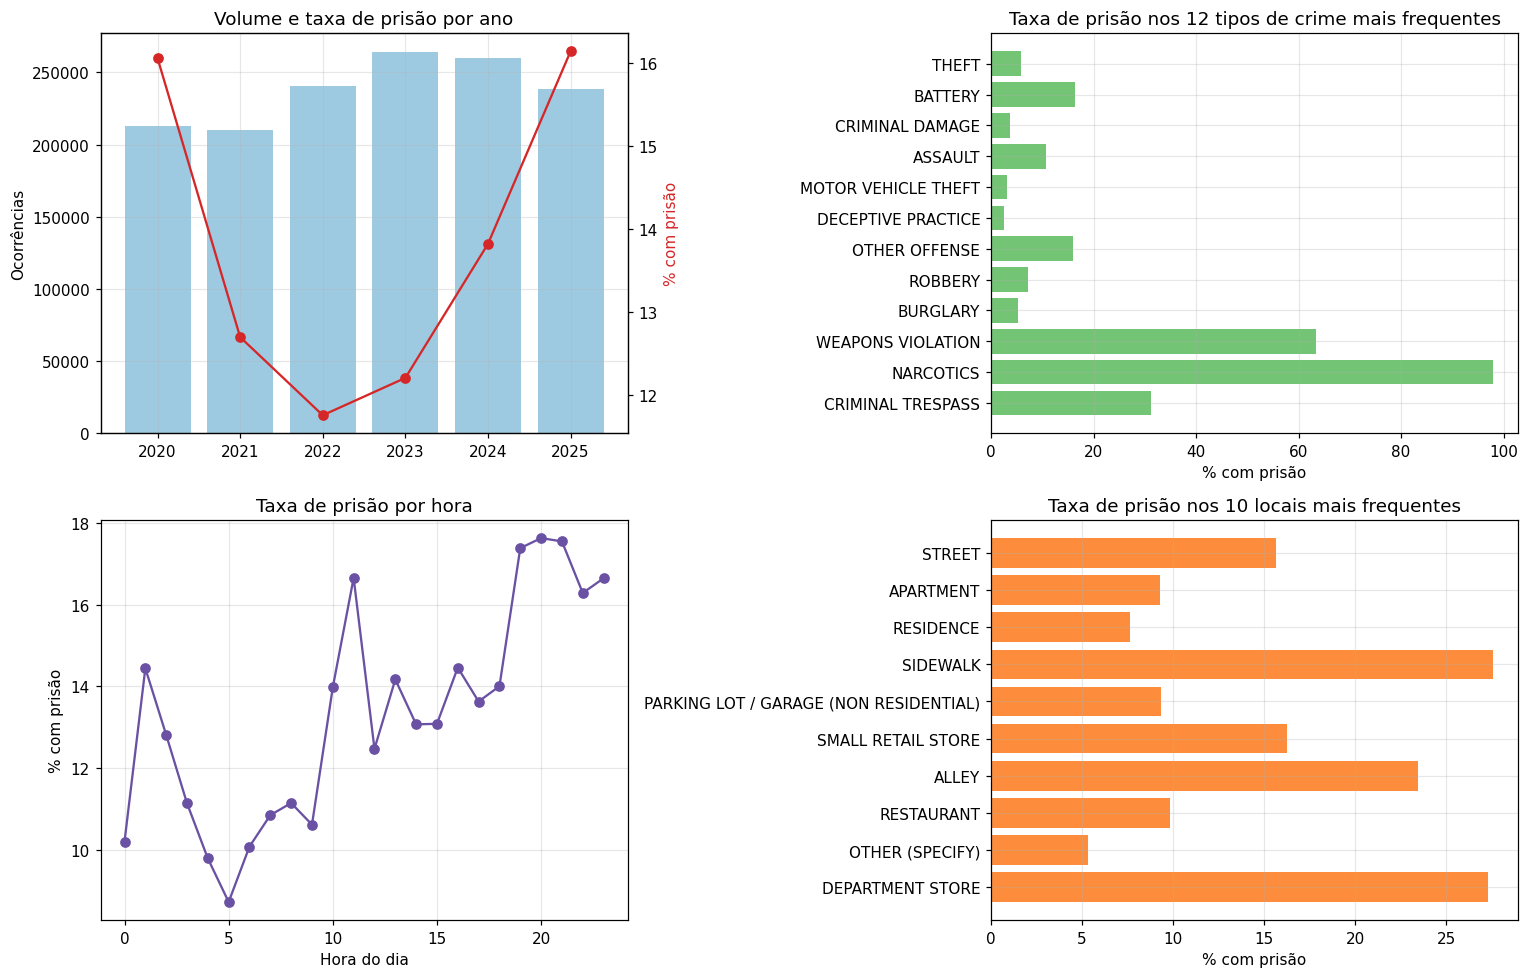

In [16]:
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# Quatro agregações no Spark (volume e taxa de prisão = média do label 0/1). Só tabelas minúsculas vão ao pandas.
por_ano = df_limpo.groupBy("year").agg(F.count("*").alias("n"), F.avg("label").alias("taxa")).orderBy("year").toPandas()
por_tipo = (df_limpo.groupBy("primary_type").agg(F.count("*").alias("n"), F.avg("label").alias("taxa"))
            .orderBy(F.desc("n")).limit(12).toPandas())              # 12 tipos mais frequentes
por_hora = (df_limpo.withColumn("hora", F.hour("data_ocorrencia")).groupBy("hora")
            .agg(F.count("*").alias("n"), F.avg("label").alias("taxa")).orderBy("hora").toPandas())
por_local = (df_limpo.groupBy("location_description").agg(F.count("*").alias("n"), F.avg("label").alias("taxa"))
             .orderBy(F.desc("n")).limit(10).toPandas())             # 10 locais mais frequentes

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

ax[0, 0].bar(por_ano["year"], por_ano["n"], color="#9ecae1")
ax[0, 0].set_ylabel("Ocorrências"); ax[0, 0].set_title("Volume e taxa de prisão por ano")
ax2 = ax[0, 0].twinx(); ax2.plot(por_ano["year"], por_ano["taxa"] * 100, "o-", color="#d62728"); ax2.set_ylabel("% com prisão", color="#d62728")
ax2.grid(False)

ax[0, 1].barh(por_tipo["primary_type"][::-1], por_tipo["taxa"][::-1] * 100, color="#74c476")
ax[0, 1].set_xlabel("% com prisão"); ax[0, 1].set_title("Taxa de prisão nos 12 tipos de crime mais frequentes")

ax[1, 0].plot(por_hora["hora"], por_hora["taxa"] * 100, "o-", color="#6a51a3")
ax[1, 0].set_xlabel("Hora do dia"); ax[1, 0].set_ylabel("% com prisão"); ax[1, 0].set_title("Taxa de prisão por hora")

ax[1, 1].barh(por_local["location_description"][::-1], por_local["taxa"][::-1] * 100, color="#fd8d3c")
ax[1, 1].set_xlabel("% com prisão"); ax[1, 1].set_title("Taxa de prisão nos 10 locais mais frequentes")

plt.tight_layout(); plt.show()

In [17]:
# Leitura automática dos gráficos (números desta execução)
# --- Ano ---
a_max, a_min = por_ano.loc[por_ano["taxa"].idxmax()], por_ano.loc[por_ano["taxa"].idxmin()]
amplitude = (a_max["taxa"] - a_min["taxa"]) * 100
print("ANO:")
print("  taxa de prisão por ano: " + " | ".join(f"{int(r.year)}: {r.taxa:.1%}" for r in por_ano.itertuples()))
print(f"  maior taxa em {int(a_max['year'])} ({a_max['taxa']:.1%}) e menor em {int(a_min['year'])} ({a_min['taxa']:.1%}): "
      f"oscilação de {amplitude:.1f} pontos percentuais.")
v_min, v_max = por_ano["n"].min(), por_ano["n"].max()
print(f"  volume anual entre {v_min:,} e {v_max:,} ocorrências (variação de {v_max / v_min - 1:.0%}).")
print("  -> a taxa muda ao longo do tempo sem padrão estável: justifica NÃO usar `year` como atributo e testar o modelo com divisão temporal (seção 7.7).")

# --- Tipo de crime ---
t = por_tipo.sort_values("taxa", ascending=False)
print("\nTIPO DE CRIME (entre os 12 mais frequentes):")
print("  maiores taxas: " + ", ".join(f"{r.primary_type} ({r.taxa:.0%})" for r in t.head(3).itertuples()))
print("  menores taxas: " + ", ".join(f"{r.primary_type} ({r.taxa:.1%})" for r in t.tail(4).itertuples()))
print("  -> o tipo de crime é o fator de maior variação (de ~0% a quase 100%); será explorado na seção 7.6.")

# --- Hora ---
h_min, h_max = por_hora.loc[por_hora["taxa"].idxmin()], por_hora.loc[por_hora["taxa"].idxmax()]
noite = por_hora[por_hora["hora"].between(19, 23)]["taxa"]
print("\nHORA:")
print(f"  menor taxa às {int(h_min['hora'])}h ({h_min['taxa']:.1%}); maior às {int(h_max['hora'])}h ({h_max['taxa']:.1%}); "
      f"entre 19h e 23h a taxa vai de {noite.min():.1%} a {noite.max():.1%}.")
print("  -> picos isolados (por exemplo, em horas 'redondas') sugerem horários registrados de forma aproximada.")

# --- Local ---
l = por_local.sort_values("taxa", ascending=False)
print("\nLOCAL (entre os 10 mais frequentes):")
print("  maiores taxas: " + ", ".join(f"{r.location_description} ({r.taxa:.0%})" for r in l.head(3).itertuples()))
print("  menores taxas: " + ", ".join(f"{r.location_description} ({r.taxa:.0%})" for r in l.tail(3).itertuples()))

ANO:
  taxa de prisão por ano: 2020: 16.1% | 2021: 12.7% | 2022: 11.8% | 2023: 12.2% | 2024: 13.8% | 2025: 16.1%
  maior taxa em 2025 (16.1%) e menor em 2022 (11.8%): oscilação de 4.4 pontos percentuais.
  volume anual entre 210,024 e 263,877 ocorrências (variação de 26%).
  -> a taxa muda ao longo do tempo sem padrão estável: justifica NÃO usar `year` como atributo e testar o modelo com divisão temporal (seção 7.7).

TIPO DE CRIME (entre os 12 mais frequentes):
  maiores taxas: NARCOTICS (98%), WEAPONS VIOLATION (63%), CRIMINAL TRESPASS (31%)
  menores taxas: BURGLARY (5.3%), CRIMINAL DAMAGE (3.8%), MOTOR VEHICLE THEFT (3.1%), DECEPTIVE PRACTICE (2.6%)
  -> o tipo de crime é o fator de maior variação (de ~0% a quase 100%); será explorado na seção 7.6.

HORA:
  menor taxa às 5h (8.7%); maior às 20h (17.6%); entre 19h e 23h a taxa vai de 16.3% a 17.6%.
  -> picos isolados (por exemplo, em horas 'redondas') sugerem horários registrados de forma aproximada.

LOCAL (entre os 10 mais freque

**Como ler os gráficos (a leitura com números está na célula acima, gerada a cada execução):**

- **Ano:** se a taxa de prisão oscila bastante de um ano para o outro enquanto o volume varia pouco, o padrão **não é estável no tempo**. Isso justifica não usar `year` como atributo e **testar o modelo com divisão temporal** (seção 7.7).
- **Tipo de crime:** é, em geral, o fator de maior variação. Crimes em que o registro nasce da ação policial (narcóticos, armas) têm taxas muito altas, enquanto crimes reportados depois pela vítima (furto, dano, roubo, arrombamento, fraude) têm taxas baixas. Isso será explorado na seção 7.6.
- **Hora:** compara a madrugada com a noite. Oscilações irregulares em horas "redondas" sugerem horários registrados de forma aproximada (a documentação da base avisa que a data/hora é, por vezes, uma estimativa). Parte do efeito pode vir da **composição de tipos de crime** ao longo do dia.
- **Local:** locais públicos (calçada, beco, rua) e lojas costumam ter taxas maiores que locais privados (residência, apartamento, estacionamento), coerente com o fato de a prisão ser mais provável quando o autor é encontrado no local.

> 💡 **Por que fazer assim? Benefícios:** a exploração **antes** da modelagem gera hipóteses (o tipo de crime domina; o tempo é instável) que depois **testamos** com ablação (7.8) e validação temporal (7.7). Assim os resultados dos modelos são confirmados por evidências independentes.

---
## 4. Paralelismo: evidências de que é um problema de dados massivos

Como o Spark distribuiu o trabalho?

### 4.1 Partições e desbalanceamento (*data skew*)

In [18]:
import glob
n_arquivos = len(glob.glob(f"{DIR_DADOS}/crimes_*.csv"))

print("Núcleos (tarefas simultâneas):", sc.defaultParallelism)
print("Arquivos CSV lidos            :", n_arquivos)
print("Partições na leitura dos CSVs :", raw.rdd.getNumPartitions())
print("Partições do df_limpo (cache) :", df_limpo.rdd.getNumPartitions())

# Linhas por partição: o repartition() equilibra o trabalho entre as tarefas.
# spark_partition_id() devolve o nº da partição de cada linha; contamos quantas linhas cada partição tem.
from pyspark.sql.functions import spark_partition_id
linhas_por_particao = (df_limpo.groupBy(spark_partition_id().alias("particao")).count()
                       .toPandas()["count"])
print(f"Linhas por partição: mín={linhas_por_particao.min():,} | máx={linhas_por_particao.max():,}")

# Distribuição das CHAVES de agrupamento: os tipos de crime são muito desiguais (esse é o "data skew")
skew = (df_limpo.groupBy("primary_type").count().orderBy(F.desc("count")).toPandas())
skew["% acumulado"] = (skew["count"].cumsum() / skew["count"].sum() * 100).round(1)
print(f"\nOs 3 tipos de crime mais frequentes concentram {skew['% acumulado'].iloc[2]}% das linhas "
      f"(de {len(skew)} tipos).")
display(skew.head(5))

# ===== Leitura automática =====
desbal = linhas_por_particao.max() / linhas_por_particao.min() - 1
print(f"\nLeitura: as {len(linhas_por_particao)} partições do DataFrame limpo diferem em apenas {desbal:.4%} "
      "entre a maior e a menor (dados bem distribuídos, graças ao repartition).")
top1 = skew.iloc[0]
print(f"Já as CHAVES não são uniformes: {top1['primary_type']} sozinho tem {top1['count'] / skew['count'].sum():.1%} das linhas "
      f"e os 3 maiores tipos somam {skew['% acumulado'].iloc[2]}% (data skew).")
if raw.rdd.getNumPartitions() < n_arquivos:
    print(f"Na leitura há MENOS partições ({raw.rdd.getNumPartitions()}) que arquivos ({n_arquivos}): o Spark junta arquivos pequenos "
          "na mesma partição (até ~128 MB por partição).")

Núcleos (tarefas simultâneas): 2
Arquivos CSV lidos            : 6
Partições na leitura dos CSVs : 5
Partições do df_limpo (cache) : 8
Linhas por partição: mín=178,170 | máx=178,172

Os 3 tipos de crime mais frequentes concentram 51.1% das linhas (de 33 tipos).


,primary_type,count,% acumulado
0,THEFT,310400,21.8
1,BATTERY,256243,39.8
2,CRIMINAL DAMAGE,162140,51.1
3,ASSAULT,127159,60.1
4,MOTOR VEHICLE THEFT,110274,67.8



Leitura: as 8 partições do DataFrame limpo diferem em apenas 0.0011% entre a maior e a menor (dados bem distribuídos, graças ao repartition).
Já as CHAVES não são uniformes: THEFT sozinho tem 21.8% das linhas e os 3 maiores tipos somam 51.1% (data skew).
Na leitura há MENOS partições (5) que arquivos (6): o Spark junta arquivos pequenos na mesma partição (até ~128 MB por partição).


Os dados ficam **bem distribuídos entre as partições** do DataFrame limpo graças ao `repartition`, mas as **chaves** de agrupamento **não são uniformes**: poucos tipos de crime concentram uma grande parte das linhas (os números exatos estão na célula acima). Em um `groupBy("primary_type")`, todas as linhas da mesma chave vão para a mesma partição de *shuffle*, então a partição que recebe o tipo mais frequente fica maior que as demais (*data skew*). Como `count` e `avg` são pré-agregados dentro de cada partição, o efeito aqui é pequeno, mas em operações sem pré-agregação (*joins*, estatísticas por categoria no treino das árvores) o desbalanceamento pesa mais, e o tempo de um estágio é definido pela **tarefa mais lenta**. Com o histórico completo (milhões de linhas) e em um cluster, esse efeito se amplifica.

**Sobre a leitura dos CSVs:** com `multiLine=True`, o Spark **não consegue dividir um mesmo arquivo em blocos** (precisa lê-lo do início ao fim para saber onde cada campo entre aspas termina), então cada arquivo vira, no mínimo, uma partição. O número de partições da leitura pode ser menor que o de arquivos porque o Spark **agrupa arquivos pequenos** na mesma partição. De qualquer forma, o `repartition` logo após a limpeza recupera o equilíbrio.

> 💡 **Por que fazer assim? Benefícios:** olhar as partições mostra se o trabalho está **bem repartido** entre os núcleos. Partições desiguais deixam núcleos ociosos esperando a tarefa mais lenta. O `repartition` custa um *shuffle* uma vez, mas devolve partições equilibradas para **todas** as etapas seguintes.

### 4.2 Experimento: partições de *shuffle* × tempo

Medir uma agregação com *shuffle* (`groupBy` por tipo de crime e distrito) com diferentes valores de `spark.sql.shuffle.partitions`, usando a **mediana de 3 execuções** (reduz o efeito de uma medida ruim). O AQE é desligado só durante o experimento (ele juntaria automaticamente as partições pequenas e esconderia o efeito) e religado em seguida.

    1 partições -> 1.195 s
    2 partições -> 1.156 s
    4 partições -> 1.349 s
    8 partições -> 1.004 s
   16 partições -> 1.112 s
   50 partições -> 2.177 s
  200 partições -> 2.986 s
 1000 partições -> 10.117 s


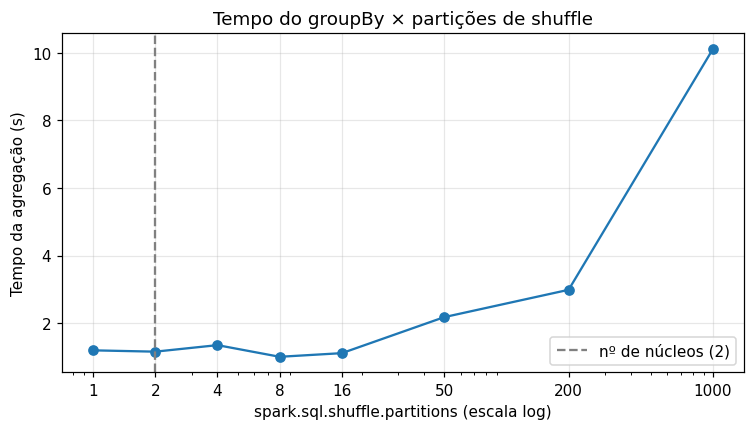


spark.sql.shuffle.partitions fixado em 16


In [19]:
def medir(n_part, repeticoes=3):
    """Mede o tempo (mediana de `repeticoes` execuções) de uma agregação com shuffle usando n_part partições."""
    spark.conf.set("spark.sql.shuffle.partitions", str(n_part))
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter()
        (df_limpo.groupBy("primary_type", "district_cat")
                 .agg(F.count("*"), F.avg("label")).collect())   # collect() é a ação que dispara a execução
        tempos.append(time.perf_counter() - t0)
    return sorted(tempos)[len(tempos) // 2]                      # mediana de 3 = valor do meio


spark.conf.set("spark.sql.adaptive.enabled", "false")   # desligado só aqui, para o efeito do nº de partições aparecer
valores = [1, 2, 4, 8, 16, 50, 200, 1000]
medidas = []
for n in valores:
    t = medir(n)
    medidas.append({"shuffle_partitions": n, "tempo_s": round(t, 3)})
    print(f"{n:>5} partições -> {t:.3f} s")
spark.conf.set("spark.sql.adaptive.enabled", "true")    # em uso real, o AQE fica ligado

tabela_shuffle = pd.DataFrame(medidas)
plt.figure(figsize=(8, 4))
plt.plot(tabela_shuffle["shuffle_partitions"], tabela_shuffle["tempo_s"], "o-")
plt.xscale("log"); plt.xticks(valores, [str(v) for v in valores])
plt.axvline(sc.defaultParallelism, ls="--", color="gray", label=f"nº de núcleos ({sc.defaultParallelism})")
plt.xlabel("spark.sql.shuffle.partitions (escala log)"); plt.ylabel("Tempo da agregação (s)")
plt.title("Tempo do groupBy × partições de shuffle"); plt.legend(); plt.show()

# Regra de escolha (objetiva e reproduzível): valores com pelo menos 1 partição por núcleo e até 15% acima
# do melhor tempo (diferenças pequenas são ruído); entre eles, o MAIOR, que deixa folga para dados mais pesados.
melhor_t = tabela_shuffle["tempo_s"].min()
aceitaveis = tabela_shuffle[(tabela_shuffle["shuffle_partitions"] >= sc.defaultParallelism) &
                            (tabela_shuffle["tempo_s"] <= melhor_t * 1.15)]
SHUFFLE_PARTS = int(aceitaveis["shuffle_partitions"].max())
spark.conf.set("spark.sql.shuffle.partitions", str(SHUFFLE_PARTS))
print(f"\nspark.sql.shuffle.partitions fixado em {SHUFFLE_PARTS}")

In [20]:
# Leitura automática do experimento de shuffle (números desta execução)
tmp = tabela_shuffle.set_index("shuffle_partitions")["tempo_s"]
melhor_n, melhor_t = int(tmp.idxmin()), tmp.min()
print(f"Melhor tempo: {melhor_t:.2f} s com {melhor_n} partição(ões).\n")

print("Custo relativo ao melhor tempo:")
for n in tmp.index:
    marca = "  <- padrão do Spark" if n == 200 else ("  <- escolhido" if n == SHUFFLE_PARTS else "")
    print(f"  {n:>5} partições: {tmp[n]:6.2f} s  ({tmp[n] / melhor_t:4.1f}x o melhor){marca}")

baixas = tmp[tmp.index <= 16]
print(f"\nEntre 1 e 16 partições o tempo oscila de {baixas.min():.2f} a {baixas.max():.2f} s "
      f"({baixas.max() / baixas.min():.1f}x): diferenças desse tamanho são, em boa parte, ruído de medida.")
if 200 in tmp.index and 1000 in tmp.index:
    print(f"Já 200 partições custam {tmp[200] / melhor_t:.1f}x e 1000 partições {tmp[1000] / melhor_t:.1f}x o melhor tempo: "
          "o custo fixo de agendar cada tarefa passa a dominar.")
print(f"Escolha: {SHUFFLE_PARTS} partições = {SHUFFLE_PARTS / sc.defaultParallelism:.0f} por núcleo "
      "(maior valor dentro de 15% do melhor tempo, com pelo menos 1 partição por núcleo).")

Melhor tempo: 1.00 s com 8 partição(ões).

Custo relativo ao melhor tempo:
      1 partições:   1.20 s  ( 1.2x o melhor)
      2 partições:   1.16 s  ( 1.2x o melhor)
      4 partições:   1.35 s  ( 1.3x o melhor)
      8 partições:   1.00 s  ( 1.0x o melhor)
     16 partições:   1.11 s  ( 1.1x o melhor)  <- escolhido
     50 partições:   2.18 s  ( 2.2x o melhor)
    200 partições:   2.99 s  ( 3.0x o melhor)  <- padrão do Spark
   1000 partições:  10.12 s  (10.1x o melhor)

Entre 1 e 16 partições o tempo oscila de 1.00 a 1.35 s (1.3x): diferenças desse tamanho são, em boa parte, ruído de medida.
Já 200 partições custam 3.0x e 1000 partições 10.1x o melhor tempo: o custo fixo de agendar cada tarefa passa a dominar.
Escolha: 16 partições = 8 por núcleo (maior valor dentro de 15% do melhor tempo, com pelo menos 1 partição por núcleo).


**Interpretação (os números exatos desta execução estão na célula acima):** com poucas partições o tempo fica num patamar baixo, e as pequenas oscilações entre esses valores são ruído de medida. A partir de certo ponto o tempo **cresce**, porque cada partição de *shuffle* vira uma **tarefa** com custo fixo de agendamento e de escrita/leitura do *shuffle*: com pouco mais de 1 milhão de linhas e só alguns núcleos, o trabalho útil por partição é pequeno e o custo fixo domina. Por isso o padrão do Spark (200), pensado para clusters grandes, é desperdício numa máquina pequena, e 1000 partições é ainda pior.

Foi escolhido o **maior valor dentro de 15% do melhor tempo**, com pelo menos 1 partição por núcleo: isso deixa folga para as etapas mais pesadas da modelagem (validação cruzada e treino), sem pagar o custo de centenas de tarefas. Duas ressalvas: (1) o experimento foi feito com o AQE desligado; com ele ligado, o Spark junta partições pequenas automaticamente e reduz esse custo, e por isso o padrão de 200 é menos prejudicial na prática; (2) o ponto ótimo depende do volume e do hardware: em um cluster com muitos núcleos e o histórico completo, ele se desloca para **mais** partições. Por isso o parâmetro deve ser **medido** e não fixado de cabeça. (Os tempos variam um pouco a cada execução; o que se mantém é a **forma** da curva.)

> 💡 **Por que fazer assim? Benefícios:** em vez de repetir uma "receita" da internet (200 ou 2×núcleos), **medimos** no nosso hardware e dados e usamos uma **regra objetiva**. O resultado é um ajuste justificado por evidência, e a regra se reaplica sozinha se o hardware ou o volume mudarem.

---
## 5. Engenharia de atributos e *Pipeline*

### 5.1 Divisão treino/teste

Foi separado **80% para treino** e **20% para teste** com `randomSplit` e semente fixa. Toda estatística aprendida (mediana da imputação, índices das categorias, média e desvio da padronização, pesos de classe, hiperparâmetros) usa **somente o treino**. O teste só entra na avaliação final.

In [21]:
# Divisão 80/20 com semente fixa. randomSplit sorteia cada linha de forma independente (distribuído, sem juntar os dados).
train_df, test_df = df_limpo.randomSplit([0.8, 0.2], seed=SEED)
train_df = train_df.cache()    # treino e teste serão usados muitas vezes: guarda em memória
test_df = test_df.cache()
n_train, n_test = train_df.count(), test_df.count()
print(f"Treino: {n_train:,} | Teste: {n_test:,}")

# Como o sorteio é linha a linha e independente, a proporção de prisões deve ficar parecida nos dois conjuntos
for nome, d in [("Treino", train_df), ("Teste", test_df)]:
    print(f"{nome}: {d.agg(F.avg('label')).first()[0]:.2%} das ocorrências terminam em prisão")

Treino: 1,140,802 | Teste: 284,571
Treino: 13.74% das ocorrências terminam em prisão
Teste: 13.71% das ocorrências terminam em prisão


### 5.2 Pesos de classe (calculados só no treino)

Para o modelo não "ignorar" a classe minoritária, cada ocorrência recebe um **peso** inversamente proporcional à frequência da sua classe: `peso = n_total / (2 × n_da_classe)`. Assim, as duas classes contribuem igualmente para a função de perda. A avaliação, no entanto, é feita **sem pesos** e com a distribuição real do teste.
> 💡 **Por que fazer assim? Benefícios**
> - **Pesos de classe** ensinam o modelo a "dar importância" à classe minoritária **sem** descartar dados (como o *undersampling*) nem inventar dados (como o *oversampling*). Preserva toda a informação e custa quase nada em Spark.
> - **Calcular os pesos só no treino** evita vazamento
> - **Avaliar sem pesos** mostra o desempenho na distribuição real, que é o que importa na prática.
> - **Efeito colateral importante:** os pesos **deslocam as probabilidades** (o modelo passa a "superestimar" a chance de prisão). Por isso a saída `probability` **não é uma probabilidade calibrada** e o limiar de 0,5 não tem o significado usual (ver seção 7.4).

In [22]:
def adicionar_pesos(d):
    """Calcula os pesos de classe com os dados de d (usar SEMPRE só com treino) e cria a coluna 'peso'.
    Fórmula: peso = n_total / (2 * n_da_classe). Assim a soma dos pesos das duas classes fica igual."""
    n = d.count()
    n_pos = d.filter(col("label") == 1.0).count()
    n_neg = n - n_pos
    w_pos, w_neg = n / (2 * n_pos), n / (2 * n_neg)
    return d.withColumn("peso", F.when(col("label") == 1.0, w_pos).otherwise(w_neg)), (w_neg, w_pos)


train_df, (w_neg, w_pos) = adicionar_pesos(train_df)
print(f"Peso da classe 0 (sem prisão): {w_neg:.3f} | Peso da classe 1 (prisão): {w_pos:.3f}")
print(f"Cada prisão pesa {w_pos / w_neg:.1f}x mais que cada não-prisão no treino (≈ razão entre as classes).")

Peso da classe 0 (sem prisão): 0.580 | Peso da classe 1 (prisão): 3.639
Cada prisão pesa 6.3x mais que cada não-prisão no treino (≈ razão entre as classes).


### 5.3 Atributos criados

| Atributo | Como é criado | Por quê |
|---|---|---|
| `hora_sin`, `hora_cos` | seno/cosseno de `2π·hora/24` | A hora é **cíclica**: 23h e 0h são vizinhas. A codificação circular preserva isso |
| `dia_sin`, `dia_cos` | idem, para o dia da semana (período 7) | Padrões semanais |
| `mes_sin`, `mes_cos` | idem, para o mês (período 12) | Sazonalidade |
| `fim_de_semana` | 1 se sábado/domingo | Rotina de policiamento e de ocorrências |
| `noite` | 1 se entre 22h e 6h | Contexto noturno |
| `domestico` | `domestic` como 0/1 | Contexto doméstico |
| `lat_imp`, `lon_imp` | latitude/longitude com ausentes imputados (mediana do treino) | Localização geográfica |
| `primary_type`, `iucr`, `fbi_code` | *StringIndexer* + *OneHotEncoder* | Tipo/natureza do crime |
| `location_description` | idem | Tipo de local (rua, residência...) |
| `district_cat`, `community_area_cat` | idem | Território (distrito policial e área comunitária) |

**Fora dos atributos** (para evitar vazamento ou ruído): `arrest`/`label` (o alvo), `updated_on`, `id`, `year` (um atributo de ano não generaliza para anos futuros) e as colunas descartadas na seção 3.5.

As variáveis temporais são criadas por um **`SQLTransformer` dentro do próprio *Pipeline***. Assim, o modelo salvo na seção 8 recebe a ocorrência "crua" (data, tipo, local...) e refaz **todas** as transformações sozinho, sem depender de código externo.

In [23]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import (SQLTransformer, Imputer, StringIndexer, OneHotEncoder,
                                VectorAssembler, StandardScaler)

# --- 1) Variáveis temporais e binárias, criadas DENTRO do Pipeline via SQL ---
# O SQLTransformer não "aprende" nada dos dados: só transforma cada linha. Por estar no Pipeline, o modelo salvo
# aceita a ocorrência "crua" (data, tipo, local...) e refaz tudo sozinho. __THIS__ = o DataFrame que entra na etapa.
# Seno/cosseno: a hora é CÍCLICA (23h e 0h são vizinhas) e um número simples (0..23) diria que estão distantes.
SQL_FEATURES = """
SELECT *,
       sin(2 * pi() * hour(data_ocorrencia) / 24)                  AS hora_sin,
       cos(2 * pi() * hour(data_ocorrencia) / 24)                  AS hora_cos,
       sin(2 * pi() * (dayofweek(data_ocorrencia) - 1) / 7)        AS dia_sin,
       cos(2 * pi() * (dayofweek(data_ocorrencia) - 1) / 7)        AS dia_cos,
       sin(2 * pi() * (month(data_ocorrencia) - 1) / 12)           AS mes_sin,
       cos(2 * pi() * (month(data_ocorrencia) - 1) / 12)           AS mes_cos,
       CASE WHEN dayofweek(data_ocorrencia) IN (1, 7) THEN 1.0 ELSE 0.0 END               AS fim_de_semana,
       CASE WHEN hour(data_ocorrencia) >= 22 OR hour(data_ocorrencia) < 6 THEN 1.0 ELSE 0.0 END AS noite,
       CAST(domestic AS DOUBLE)                                    AS domestico
FROM __THIS__
"""

# Listas de colunas: categóricas (viram one-hot) e numéricas (viram vetor padronizado)
cat_cols = ["primary_type", "iucr", "location_description", "fbi_code", "district_cat", "community_area_cat"]
num_cols = ["hora_sin", "hora_cos", "dia_sin", "dia_cos", "mes_sin", "mes_cos",
            "fim_de_semana", "noite", "domestico", "lat_imp", "lon_imp"]

# --- 2) Etapas do Pipeline (cada uma é um Transformer ou um Estimator do Spark ML) ---
sql_feat = SQLTransformer(statement=SQL_FEATURES)
# Imputer (Estimator): aprende a MEDIANA do treino e preenche latitude/longitude ausentes
imputer = Imputer(inputCols=["latitude", "longitude"], outputCols=["lat_imp", "lon_imp"], strategy="median")
# StringIndexer (Estimator): texto -> índice numérico; handleInvalid="keep" manda categoria nova para um índice "desconhecido"
indexer = StringIndexer(inputCols=cat_cols, outputCols=[c + "_idx" for c in cat_cols],
                        handleInvalid="keep")
# OneHotEncoder: índice -> vetor binário esparso (sem ordem artificial entre categorias)
encoder = OneHotEncoder(inputCols=[c + "_idx" for c in cat_cols], outputCols=[c + "_vec" for c in cat_cols],
                        handleInvalid="keep")
assembler_num = VectorAssembler(inputCols=num_cols, outputCol="features_num")          # junta as numéricas
scaler = StandardScaler(inputCol="features_num", outputCol="features_num_scaled", withMean=True, withStd=True)
assembler_final = VectorAssembler(inputCols=["features_num_scaled"] + [c + "_vec" for c in cat_cols],
                                  outputCol="features")                                 # vetor final do modelo

prep_stages = [sql_feat, imputer, indexer, encoder, assembler_num, scaler, assembler_final]

# Exemplo do resultado das transformações temporais (5 linhas)
sql_feat.transform(df_limpo.limit(5)).select("data_ocorrencia", "hora_sin", "hora_cos",
                                              "fim_de_semana", "noite", "domestico").show(5, truncate=False)

+-------------------+-------------------+-------------------+-------------+-----+---------+
|data_ocorrencia    |hora_sin           |hora_cos           |fim_de_semana|noite|domestico|
+-------------------+-------------------+-------------------+-------------+-----+---------+
|2024-07-15 00:00:00|0.0                |1.0                |0.0          |1.0  |0.0      |
|2024-10-13 22:00:00|-0.5000000000000004|0.8660254037844384 |1.0          |1.0  |0.0      |
|2022-08-27 03:00:00|0.7071067811865475 |0.7071067811865476 |1.0          |1.0  |0.0      |
|2021-02-28 19:00:00|-0.9659258262890684|0.2588190451025203 |1.0          |0.0  |1.0      |
|2023-01-26 13:00:00|-0.2588190451025208|-0.9659258262890683|0.0          |0.0  |0.0      |
+-------------------+-------------------+-------------------+-------------+-----+---------+



### 5.4 O que cada etapa do *Pipeline* faz

| Etapa | O que faz | Por quê |
|---|---|---|
| `SQLTransformer` | Cria as variáveis temporais e binárias | Extrai estrutura preditiva dos campos brutos |
| `Imputer` | Preenche latitude/longitude ausentes com a **mediana do treino** | Os algoritmos não aceitam ausentes; a mediana é robusta a valores extremos |
| `StringIndexer` | Categoria → índice numérico (6 colunas de uma vez) | Algoritmos só operam sobre números. `handleInvalid="keep"` evita erro com categorias novas |
| `OneHotEncoder` | Índice → vetor binário **esparso** | Evita que o modelo interprete uma ordem inexistente entre as categorias |
| `VectorAssembler` (1º) | Junta as colunas numéricas em um vetor | Formato exigido pelo Spark ML |
| `StandardScaler` | Padroniza só as numéricas (média 0, desvio 1) | Atributos em escalas diferentes passam a ter peso comparável. O *one-hot* já está em 0/1 e não é padronizado |
| `VectorAssembler` (final) | Junta numéricas padronizadas + categóricas codificadas → `features` | Vetor final de entrada do modelo |

**Ponto central (sem vazamento):** o `fit` do Pipeline aprende mediana, índices, média e desvio **apenas com o treino**; o `transform` aplica esses valores iguais ao treino e ao teste. Na busca de hiperparâmetros (seção 6) o **Pipeline inteiro** é refeito dentro de cada *fold*, de modo que nem os dados de validação "vazam" para o pré-processamento.


> 💡 **Por que fazer assim? Benefícios do `Pipeline`**
> - **Zero vazamento:** `fit` aprende tudo só com o treino; o `transform` aplica os mesmos valores no teste.
> - **Reprodutibilidade:** um único objeto contém **todo** o caminho do dado cru até a previsão e pode ser salvo e recarregado (seção 8).
> - **Validação correta:** no `CrossValidator`, o Pipeline inteiro é refeito em cada *fold*, o que dá uma estimativa honesta do desempenho.
> - **Vetores esparsos:** o *one-hot* guarda só as posições com valor 1, economizando memória e tempo (essencial com muitas colunas).

In [24]:
# fit() APENAS no treino: aqui o Spark aprende a mediana, os índices das categorias, média e desvio das numéricas.
prep_modelo = Pipeline(stages=prep_stages).fit(train_df)
amostra_prep = prep_modelo.transform(train_df.limit(2000))     # transform numa amostra pequena só para inspecionar

dimensao = amostra_prep.select("features").first()[0].size
print(f"Dimensão do vetor de atributos: {dimensao} colunas "
      f"({len(num_cols)} numéricas + {dimensao - len(num_cols)} do one-hot)")
print("Mediana de latitude/longitude aprendida no treino:",
      [round(v, 4) for v in prep_modelo.stages[1].surrogateDF.first()])


def nomes_features(df_prep, coluna="features"):
    """Recupera o nome de cada posição do vetor `features` a partir dos metadados do Spark.
    Necessário para interpretar importâncias e coeficientes (o vetor em si só tem posições numéricas)."""
    attrs = df_prep.schema[coluna].metadata["ml_attr"]["attrs"]
    itens = [a for grupo in attrs.values() for a in grupo]
    nomes = []
    for a in sorted(itens, key=lambda a: a["idx"]):
        n = a["name"]
        if n.startswith("features_num_scaled_"):                 # o StandardScaler não propaga os nomes originais
            n = num_cols[int(n.rsplit("_", 1)[1])]
        nomes.append(n)
    return nomes


def variavel_original(nome):
    """Agrupa as colunas do one-hot na variável de origem (ex.: 'primary_type_vec_THEFT' -> 'primary_type')."""
    if "_vec_" in nome:
        return nome.split("_vec_")[0]
    for prefixo, rotulo in [("hora_", "hora (sin/cos)"), ("dia_", "dia da semana (sin/cos)"),
                            ("mes_", "mês (sin/cos)"), ("lat_", "latitude"), ("lon_", "longitude")]:
        if nome.startswith(prefixo):
            return rotulo
    return nome


NOMES = nomes_features(amostra_prep)
print("Exemplos de nomes de atributos:", NOMES[:3], "...", NOMES[-2:])

Dimensão do vetor de atributos: 728 colunas (11 numéricas + 717 do one-hot)
Mediana de latitude/longitude aprendida no treino: [41.862, -87.6624]
Exemplos de nomes de atributos: ['hora_sin', 'hora_cos', 'dia_sin'] ... ['community_area_cat_vec_9', 'community_area_cat_vec___unknown']


---
## 6. Modelagem

Modelos comparados (todos com **pesos de classe**, treinados só no treino):

| Modelo | Papel |
|---|---|
| **Baseline 1 — classe majoritária** | Referência mínima: "nunca há prisão" |
| **Baseline 2 — Regressão Logística só com `primary_type`** | Referência de "quanto se explica só pelo tipo de crime" |
| **Regressão Logística** (todos os atributos) | Modelo **linear**, rápido e interpretável |
| **Random Forest** (todos os atributos) | Conjunto de árvores: captura **não linearidades e interações** (por exemplo, "tipo de crime × local × hora") |

### 6.1 Ajuste de hiperparâmetros (sem olhar o teste)

- **Regressão Logística:** *validação cruzada* de 3 *folds* sobre uma amostra do treino, variando a regularização (`regParam`). A grade foi definida de forma exploratória: quando o melhor valor cai **na borda** da grade, ela deve ser **estendida**. A célula de verificação logo após as buscas **confere isso automaticamente** e avisa se o melhor valor ficou na borda ou se a diferença para o 2º colocado é pequena demais para ser relevante.
- **Random Forest:** `TrainValidationSplit` (uma única divisão 80/20 do treino) sobre a mesma amostra, por ser bem mais cara que a validação cruzada. O fator relevante explorado é a profundidade máxima (`maxDepth`); a mesma verificação de borda é aplicada.
- **Métrica de seleção:** **AUC-PR** (área sob a curva precisão-recall), a mais adequada com classes desbalanceadas.
- O estimador de cada busca é o **Pipeline completo** (pré-processamento + modelo): o pré-processamento é refeito em cada *fold*.
- As buscas usam `FRACAO_TUNING` do treino, para caber no Colab. Os modelos **finais** são treinados com o treino completo.

> 💡 **Por que fazer assim? Benefícios**
> - **Validação cruzada (LR):** a média de *k* divisões dá uma estimativa **mais estável** que uma única divisão. Compensa porque a regressão logística é barata.
> - **`TrainValidationSplit` (RF):** custa 1 treino por combinação (contra *k* da validação cruzada). Para um modelo caro, é o compromisso certo entre rigor e tempo.
> - **Amostra do treino no tuning:** os hiperparâmetros que ganham numa amostra costumam ser os mesmos do conjunto todo, e o tempo de busca cai muito.
> - **Tuning sem olhar o teste:** o teste fica "virgem" para a avaliação final, e a nota reportada não é otimista.

In [25]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator, TrainValidationSplit

# Avaliadores do Spark ML. Ambos usam a coluna "rawPrediction" (o escore do modelo) e NÃO usam pesos:
# a avaliação acontece na distribuição real das classes.
ev_pr = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderPR")
ev_roc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction", metricName="areaUnderROC")

# --- Estimadores: Pipeline completo = pré-processamento + classificador ---
# weightCol="peso": aplica os pesos de classe da seção 5.2.
# standardization=False na LR: as numéricas JÁ foram padronizadas pelo Pipeline (não padronizar duas vezes).
lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso",
                        maxIter=50, standardization=False)
# numTrees=30 só durante a BUSCA (rápida); o modelo final usa NUM_ARVORES_FINAL. maxBins=32 basta porque o
# one-hot gera atributos binários.
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="peso",
                            numTrees=30, maxBins=32, maxMemoryInMB=512, seed=SEED)

pipe_lr = Pipeline(stages=prep_stages + [lr])
pipe_rf = Pipeline(stages=prep_stages + [rf])

# Amostra do treino para a busca de hiperparâmetros (cache, porque será relida em cada fold)
amostra_tuning = train_df.sample(False, FRACAO_TUNING, SEED).cache()
print(f"Amostra para tuning: {amostra_tuning.count():,} linhas ({FRACAO_TUNING:.0%} do treino)")

Amostra para tuning: 285,934 linhas (25% do treino)


In [26]:
# ---------------- Regressão Logística: validação cruzada ----------------
# Grade de busca guardada em variáveis para a célula de verificação de borda (logo após a RF).
VALORES_REGPARAM = [0.0, 1e-5, 1e-4, 1e-3]
grid_lr = (ParamGridBuilder()
           .addGrid(lr.regParam, VALORES_REGPARAM)     # força da regularização (0 = nenhuma)
           .addGrid(lr.elasticNetParam, [0.0])         # 0.0 = só L2 (ridge)
           .build())

tempo_cv_lr = None
if EXECUTAR_TUNING:
    t0 = time.time()
    cv = CrossValidator(estimator=pipe_lr, estimatorParamMaps=grid_lr, evaluator=ev_pr,
                        numFolds=3, parallelism=2, seed=SEED)   # parallelism=2: treina 2 modelos ao mesmo tempo
    cv_model = cv.fit(amostra_tuning)
    resultados_lr = pd.DataFrame([
        {**{p.name: v for p, v in pm.items()}, "AUC-PR médio (CV)": round(m, 4)}
        for pm, m in zip(grid_lr, cv_model.avgMetrics)])
    display(resultados_lr.sort_values("AUC-PR médio (CV)", ascending=False))
    melhor_lr = grid_lr[int(np.argmax(cv_model.avgMetrics))]
    tempo_cv_lr = time.time() - t0
    print(f"Tempo da validação cruzada: {tempo_cv_lr:.0f} s")
else:
    melhor_lr = {lr.regParam: 1e-5, lr.elasticNetParam: 0.0}   # valor padrão quando o tuning está desligado

print("Melhores hiperparâmetros (LR):", {p.name: v for p, v in melhor_lr.items()})

,regParam,elasticNetParam,AUC-PR médio (CV)
1,0.00001,0.0,0.7015
0,0.00000,0.0,0.6996
2,0.00010,0.0,0.6967
3,0.00100,0.0,0.6755


Tempo da validação cruzada: 378 s
Melhores hiperparâmetros (LR): {'regParam': 1e-05, 'elasticNetParam': 0.0}


In [27]:
# ---------------- Random Forest: TrainValidationSplit ----------------
VALORES_DEPTH = [12, 16, 20]
grid_rf = (ParamGridBuilder()
           .addGrid(rf.maxDepth, VALORES_DEPTH)        # profundidade máxima das árvores (mais fundo = mais interações)
           .addGrid(rf.minInstancesPerNode, [1])       # tamanho mínimo de folha (fixo: teve pouco efeito)
           .build())

tempo_tvs_rf = None
if EXECUTAR_TUNING:
    t0 = time.time()
    tvs = TrainValidationSplit(estimator=pipe_rf, estimatorParamMaps=grid_rf, evaluator=ev_pr,
                               trainRatio=0.8, parallelism=1, seed=SEED)
    tvs_model = tvs.fit(amostra_tuning)
    resultados_rf = pd.DataFrame([
        {**{p.name: v for p, v in pm.items()}, "AUC-PR (validação)": round(m, 4)}
        for pm, m in zip(grid_rf, tvs_model.validationMetrics)])
    display(resultados_rf.sort_values("AUC-PR (validação)", ascending=False))
    melhor_rf = grid_rf[int(np.argmax(tvs_model.validationMetrics))]
    tempo_tvs_rf = time.time() - t0
    print(f"Tempo da validação: {tempo_tvs_rf:.0f} s")
else:
    melhor_rf = {rf.maxDepth: 20, rf.minInstancesPerNode: 1}

print("Melhores hiperparâmetros (RF):", {p.name: v for p, v in melhor_rf.items()})
_ = amostra_tuning.unpersist()   # libera a memória da amostra do tuning

,maxDepth,minInstancesPerNode,AUC-PR (validação)
2,20,1,0.6779
1,16,1,0.6669
0,12,1,0.6440


Tempo da validação: 772 s
Melhores hiperparâmetros (RF): {'maxDepth': 20, 'minInstancesPerNode': 1}


In [28]:
# Verificação automática da grade de hiperparâmetros
# Duas perguntas: (1) o melhor valor ficou na BORDA da grade? (então a busca deveria ser estendida)
#                 (2) a diferença para o 2º colocado é grande ou é praticamente empate?
LIMITE_EMPATE = 0.005   # diferença de AUC-PR abaixo disso é tratada como empate prático (critério adotado aqui)


def verifica_grade(nome, valores, melhor, metricas):
    ordenadas = sorted(metricas, reverse=True)
    dif = ordenadas[0] - ordenadas[1] if len(ordenadas) > 1 else float("nan")
    print(f"{nome}:")
    print(f"  melhor valor = {melhor} | grade = {valores}")
    if melhor in (min(valores), max(valores)):
        lado = "inferior" if melhor == min(valores) else "superior"
        print(f"  ⚠️ O melhor valor está na borda {lado} da grade: um valor além dela poderia ser ainda melhor.")
    else:
        print("  ✓ O melhor valor está no interior da grade (a busca cobriu os dois lados).")
    print(f"  diferença de AUC-PR para o 2º colocado: {dif:.4f}", end="")
    print("  -> praticamente empate (a escolha não é relevante)." if dif < LIMITE_EMPATE else "  -> diferença relevante.")


if EXECUTAR_TUNING:
    verifica_grade("Regressão Logística (regParam)", VALORES_REGPARAM, melhor_lr[lr.regParam], cv_model.avgMetrics)
    verifica_grade("Random Forest (maxDepth)", VALORES_DEPTH, melhor_rf[rf.maxDepth], tvs_model.validationMetrics)
else:
    print("Tuning desligado: usando hiperparâmetros fixos.")

Regressão Logística (regParam):
  melhor valor = 1e-05 | grade = [0.0, 1e-05, 0.0001, 0.001]
  ✓ O melhor valor está no interior da grade (a busca cobriu os dois lados).
  diferença de AUC-PR para o 2º colocado: 0.0018  -> praticamente empate (a escolha não é relevante).
Random Forest (maxDepth):
  melhor valor = 20 | grade = [12, 16, 20]
  ⚠️ O melhor valor está na borda superior da grade: um valor além dela poderia ser ainda melhor.
  diferença de AUC-PR para o 2º colocado: 0.0110  -> diferença relevante.


### 6.2 Treino final (treino completo) e baselines

Com os hiperparâmetros escolhidos, foi treinado os modelos finais com **todo o conjunto de treino**. O `fit` do Pipeline aprende o pré-processamento e o classificador juntos, **apenas no treino**.
> 💡 **Por que fazer assim? Benefícios:** treinar o modelo final com **todo** o treino (e não só com a amostra do tuning) usa toda a informação disponível. Salvar a LR logo após o treino protege o trabalho caso a sessão do Colab caia durante a Random Forest (demorada). E o *baseline* só com o tipo de crime responde: *quanto do resultado vem de saber apenas o tipo?*

In [29]:
# --- Regressão Logística final: hiperparâmetros escolhidos + TODO o treino ---
t0 = time.time()
modelo_lr = pipe_lr.copy(melhor_lr).fit(train_df)      # .copy(params) aplica os melhores hiperparâmetros ao Pipeline
tempo_lr = time.time() - t0
print(f"Regressão Logística treinada em {tempo_lr:.0f} s")
modelo_lr.write().overwrite().save(f"{DIR_MODELOS}/modelo_lr_prisao_chicago")   # salva já, caso a sessão caia durante a RF

# --- Random Forest final: melhores hiperparâmetros + mais árvores (a busca usou menos árvores para ser rápida) ---
t0 = time.time()
rf_final = rf.copy(melhor_rf).setNumTrees(NUM_ARVORES_FINAL)
modelo_rf = Pipeline(stages=prep_stages + [rf_final]).fit(train_df)
tempo_rf = time.time() - t0
print(f"Random Forest ({NUM_ARVORES_FINAL} árvores) treinada em {tempo_rf:.0f} s")

# Conferência: os hiperparâmetros escolhidos foram mesmo aplicados nos modelos finais?
print("LR: regParam =", modelo_lr.stages[-1].getRegParam(), "| elasticNetParam =", modelo_lr.stages[-1].getElasticNetParam())
print("RF: maxDepth =", modelo_rf.stages[-1].getMaxDepth(), "| minInstancesPerNode =",
      modelo_rf.stages[-1].getMinInstancesPerNode(), "| árvores =", modelo_rf.stages[-1].getNumTrees)

# --- Baseline 2: regressão logística usando SÓ o tipo de crime (referência de "o que o tipo sozinho explica") ---
b_idx = StringIndexer(inputCol="primary_type", outputCol="tipo_idx", handleInvalid="keep")
b_enc = OneHotEncoder(inputCol="tipo_idx", outputCol="tipo_vec", handleInvalid="keep")
b_asm = VectorAssembler(inputCols=["tipo_vec"], outputCol="features")
b_lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso", maxIter=50)
modelo_base = Pipeline(stages=[b_idx, b_enc, b_asm, b_lr]).fit(train_df)

# --- Predições no TESTE (primeira vez que o teste é usado) ---
# cache(): as predições serão reaproveitadas em métricas, curvas, limiares e análises por grupo.
pred_lr = modelo_lr.transform(test_df).cache()
pred_rf = modelo_rf.transform(test_df).cache()
pred_base = modelo_base.transform(test_df).cache()
print("Linhas de teste previstas:", pred_rf.count())

Regressão Logística treinada em 57 s
Random Forest (60 árvores) treinada em 2177 s
LR: regParam = 1e-05 | elasticNetParam = 0.0
RF: maxDepth = 20 | minInstancesPerNode = 1 | árvores = 60
Linhas de teste previstas: 284571


---
## 7. Avaliação e interpretação

### 7.1 Métricas

| Métrica | O que mede | Por que importa aqui |
|---|---|---|
| **AUC-ROC** | Capacidade de **ordenar**: chance de o modelo dar escore maior a uma ocorrência com prisão que a uma sem. 0,5 = acaso | Não depende do limiar. Pode parecer otimista com classes muito desbalanceadas |
| **AUC-PR** | Área sob a curva precisão × recall. A referência (acaso) é a **prevalência** da classe positiva | A mais exigente com classes desbalanceadas |
| **Precisão** (classe 1) | Das ocorrências que o modelo apontou como "prisão", quantas realmente tiveram | Custo de alarmes falsos |
| **Recall** (classe 1) | Das ocorrências que tiveram prisão, quantas o modelo encontrou | Custo de prisões "perdidas" |
| **F1** (classe 1) | Média harmônica de precisão e recall da classe positiva | Resume o equilíbrio. Calculada **para a classe minoritária**, e não ponderada |
| **F1 ponderado** | F1 médio das duas classes, ponderado pelo tamanho | Mostrado só para comparação: é dominado pela classe majoritária |
| **Matriz de confusão** | VN, FP, FN, VP | Mostra onde o modelo erra |
> 💡 **Por que fazer assim? Benefícios:** um **conjunto de métricas** (e não uma só) mostra o desempenho por ângulos diferentes: ordenação (AUC-ROC), qualidade da classe rara (AUC-PR, precisão, recall, F1) e tipos de erro (matriz de confusão). Comparar com **baselines** dá contexto: um AUC-PR de 0,7 só é "bom" se o ponto de partida for muito menor.

In [30]:
def avaliar(pred, nome):
    """Calcula as métricas no conjunto de teste (distribuição real, sem pesos)."""
    # AUCs: avaliadores nativos do Spark ML (rawPrediction = escore do modelo)
    auc_roc = ev_roc.evaluate(pred)
    auc_pr = ev_pr.evaluate(pred)
    f1_pond = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction",
                                                metricName="f1").evaluate(pred)
    # Matriz de confusão: o Spark conta (label, prediction) de forma distribuída; só 4 números chegam ao Python
    cm = {(r["label"], r["prediction"]): r["count"]
          for r in pred.groupBy("label", "prediction").count().collect()}
    vp, fp = cm.get((1.0, 1.0), 0), cm.get((0.0, 1.0), 0)
    fn, vn = cm.get((1.0, 0.0), 0), cm.get((0.0, 0.0), 0)
    prec = vp / (vp + fp) if (vp + fp) else 0.0          # dos alertas, quantos acertaram
    rec = vp / (vp + fn) if (vp + fn) else 0.0           # das prisões reais, quantas foram encontradas
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0   # F1 da classe 1 (não ponderado)
    linha = {"Modelo": nome, "AUC-ROC": auc_roc, "AUC-PR": auc_pr, "Precisão (cl. 1)": prec,
             "Recall (cl. 1)": rec, "F1 (cl. 1)": f1, "F1 ponderado": f1_pond,
             "Acurácia": (vp + vn) / (vp + vn + fp + fn)}
    return linha, np.array([[vn, fp], [fn, vp]])


prev_teste = test_df.agg(F.avg("label")).first()[0]
# Baseline 1: sempre prever "sem prisão". Não tem escore, então os valores são os TEÓRICOS de um modelo sem poder
# preditivo: AUC-ROC = 0,5 e AUC-PR = prevalência. O F1 ponderado segue da fórmula (precisão=1-p e recall=1 na classe 0).
linha_b1 = {"Modelo": "Baseline 1 — sempre 'sem prisão'", "AUC-ROC": 0.5, "AUC-PR": prev_teste,
            "Precisão (cl. 1)": 0.0, "Recall (cl. 1)": 0.0, "F1 (cl. 1)": 0.0,
            "F1 ponderado": 2 * (1 - prev_teste) ** 2 / (2 - prev_teste), "Acurácia": 1 - prev_teste}

linhas, matrizes = [linha_b1], {}
for nome, pred in [("Baseline 2 — LR só com tipo de crime", pred_base),
                   ("Regressão Logística", pred_lr),
                   ("Random Forest", pred_rf)]:
    linha, cm = avaliar(pred, nome)
    linhas.append(linha)
    matrizes[nome] = cm

tabela_final = pd.DataFrame(linhas).set_index("Modelo")
display(tabela_final.round(4))
print(f"Prevalência de prisões no teste: {prev_teste:.2%}  (= AUC-PR de um modelo sem poder preditivo)")

,AUC-ROC,AUC-PR,Precisão (cl. 1),Recall (cl. 1),F1 (cl. 1),F1 ponderado,Acurácia
Modelo,,,,,,,
Baseline 1 — sempre 'sem prisão',0.5000,0.1371,0.0000,0.0000,0.0000,0.7994,0.8629
Baseline 2 — LR só com tipo de crime,0.8034,0.5838,0.2969,0.7259,0.4214,0.7663,0.7267
Regressão Logística,0.8893,0.7032,0.3816,0.7951,0.5157,0.8216,0.7953
Random Forest,0.8786,0.6855,0.3817,0.7722,0.5109,0.8226,0.7973


Prevalência de prisões no teste: 13.71%  (= AUC-PR de um modelo sem poder preditivo)


### 7.2 Matrizes de confusão

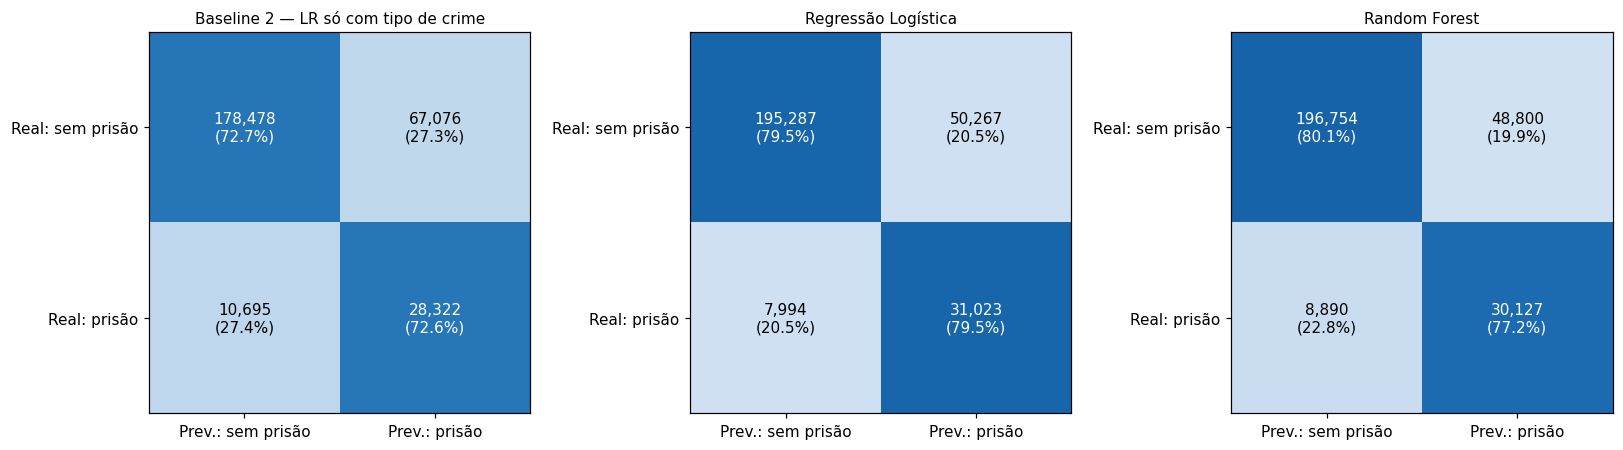

In [31]:
# Cada matriz mostra contagens e, entre parênteses, a % da LINHA (= recall de cada classe real).
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (nome, cm) in zip(ax, matrizes.items()):
    cm_norm = cm / cm.sum(axis=1, keepdims=True)           # normaliza por linha (= recall de cada classe)
    a.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}\n({cm_norm[i, j]:.1%})", ha="center", va="center",
                   color="white" if cm_norm[i, j] > 0.5 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["Prev.: sem prisão", "Prev.: prisão"])
    a.set_yticks([0, 1]); a.set_yticklabels(["Real: sem prisão", "Real: prisão"])
    a.set_title(nome, fontsize=10); a.grid(False)
plt.tight_layout(); plt.show()

### 7.3 Curvas ROC e Precisão × Recall

Para não trazer o conjunto de teste inteiro ao pandas, as curvas são calculadas **no Spark**: as probabilidades são divididas em faixas (*bins*), contando positivos e negativos por faixa e acumulamos. Só as ~200 faixas vão para o pandas.
> 💡 **Por que fazer assim? Benefícios:** calcular as curvas **no Spark** (faixas de probabilidade + soma acumulada) leva ao pandas só ~200 linhas, em vez de 280 mil predições. Isso funciona igual com bilhões de linhas.

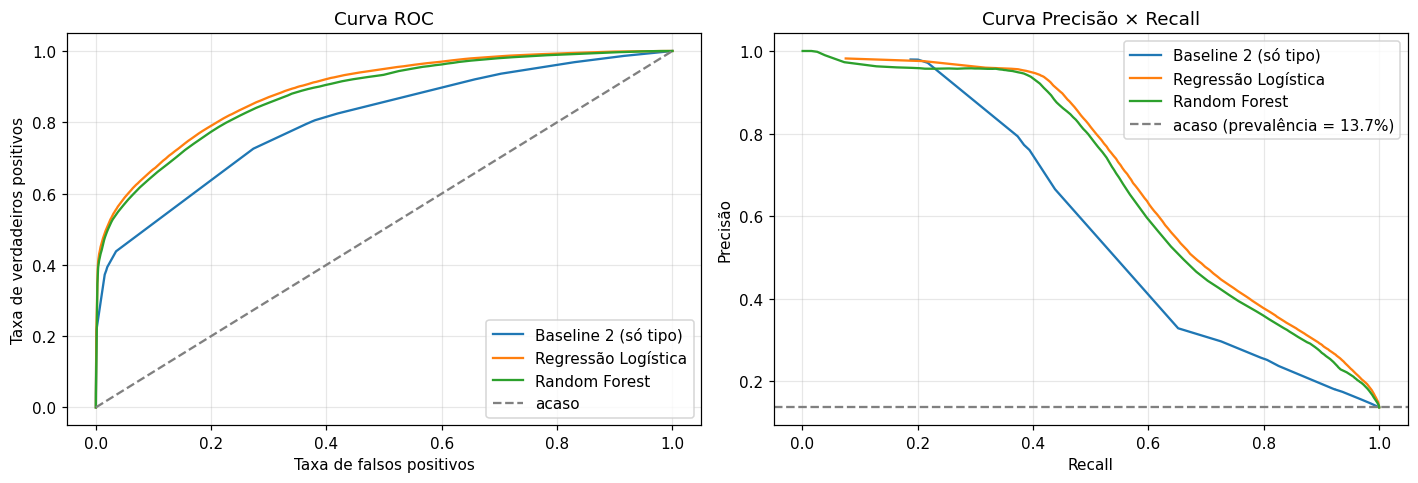

In [32]:
from pyspark.ml.functions import vector_to_array


def curvas(pred, bins=200):
    """Curvas ROC e Precisão×Recall calculadas no Spark.
    Ideia: dividir a probabilidade em `bins` faixas, contar positivos/negativos por faixa e acumular da maior
    para a menor probabilidade (equivale a varrer todos os limiares possíveis)."""
    p1 = vector_to_array(col("probability"))[1]            # probabilidade da classe 1 (vector -> array -> posição 1)
    d = (pred.select(F.floor(p1 * bins).alias("faixa"), "label")
         .groupBy("faixa").agg(F.sum("label").alias("pos"), F.count("*").alias("n"))
         .toPandas().sort_values("faixa", ascending=False))
    pos_tot, neg_tot = d["pos"].sum(), (d["n"] - d["pos"]).sum()
    vp = d["pos"].cumsum()                                 # verdadeiros positivos acumulados
    fp = (d["n"] - d["pos"]).cumsum()                      # falsos positivos acumulados
    roc = pd.DataFrame({"fpr": np.r_[0, fp / neg_tot], "tpr": np.r_[0, vp / pos_tot]})
    pr = pd.DataFrame({"recall": vp / pos_tot, "precisao": vp / (vp + fp)})
    return roc, pr


fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for nome, pred in [("Baseline 2 (só tipo)", pred_base), ("Regressão Logística", pred_lr), ("Random Forest", pred_rf)]:
    roc, pr = curvas(pred)
    ax[0].plot(roc["fpr"], roc["tpr"], label=nome)
    ax[1].plot(pr["recall"], pr["precisao"], label=nome)
ax[0].plot([0, 1], [0, 1], "--", color="gray", label="acaso")
ax[0].set_xlabel("Taxa de falsos positivos"); ax[0].set_ylabel("Taxa de verdadeiros positivos"); ax[0].set_title("Curva ROC"); ax[0].legend()
ax[1].axhline(prev_teste, ls="--", color="gray", label=f"acaso (prevalência = {prev_teste:.1%})")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precisão"); ax[1].set_title("Curva Precisão × Recall"); ax[1].legend()
plt.tight_layout(); plt.show()

### 7.4 Sensibilidade ao limiar de decisão

Por padrão, o modelo prevê "prisão" quando a probabilidade é ≥ 0,5. Em problemas desbalanceados, vale ver como precisão e recall mudam com o limiar. **Esta tabela é descritiva**: ela mostra o equilíbrio de cada limiar, e o limiar usado nas métricas acima **não foi escolhido** com base no teste. Em uma aplicação real, o limiar seria escolhido num conjunto de validação separado, conforme o custo de cada tipo de erro.
> 💡 **Por que fazer assim? Benefícios:** mostrar a troca precisão × recall em vários limiares evita a ilusão de que existe "um único" resultado do modelo. Quem for usar decide o limiar conforme o **custo** de cada erro (alarme falso × prisão perdida).

In [33]:
def sensibilidade_limiar(pred, limiares):
    """Precisão, recall e F1 da classe 1 para vários limiares, em UMA passagem pelos dados."""
    p1 = vector_to_array(col("probability"))[1]
    base = pred.select(p1.alias("p1"), "label")
    exprs = []
    for i, t in enumerate(limiares):                       # para cada limiar, somamos VP, FP e FN
        prev_pos = col("p1") >= t
        exprs += [F.sum((prev_pos & (col("label") == 1)).cast("int")).alias(f"vp{i}"),
                  F.sum((prev_pos & (col("label") == 0)).cast("int")).alias(f"fp{i}"),
                  F.sum((~prev_pos & (col("label") == 1)).cast("int")).alias(f"fn{i}")]
    r = base.agg(*exprs).first()
    linhas = []
    for i, t in enumerate(limiares):
        vp, fp, fn = r[f"vp{i}"], r[f"fp{i}"], r[f"fn{i}"]
        prec = vp / (vp + fp) if (vp + fp) else 0.0
        rec = vp / (vp + fn) if (vp + fn) else 0.0
        linhas.append({"limiar": t, "precisão": prec, "recall": rec,
                       "F1": 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0})
    return pd.DataFrame(linhas).set_index("limiar").round(3)


LIMIARES = [0.3, 0.4, 0.5, 0.6, 0.7]
print("Random Forest:")
sens_rf = sensibilidade_limiar(pred_rf, LIMIARES)    # guardada: usada na leitura automática da seção 7.9
display(sens_rf)

Random Forest:


,precisão,recall,F1
limiar,,,
0.3,0.227,0.936,0.366
0.4,0.279,0.893,0.425
0.5,0.382,0.772,0.511
0.6,0.768,0.513,0.615
0.7,0.929,0.404,0.563


### 7.5 Quais atributos pesam mais? (interpretação)

- **Random Forest:** importância de cada atributo (redução de impureza somada nas árvores), **agrupada por variável de origem** e depois por **conceito**: `iucr`, `fbi_code` e `primary_type` descrevem a mesma coisa (a natureza do crime) e dividem a importância entre si, então só o grupo mostra o peso real da natureza do crime.
- **Regressão Logística:** coeficientes e *odds ratio* (`exp(coeficiente)`). Para atributos binários (*one-hot*), é o fator de multiplicação da chance de prisão quando aquela categoria está presente, mantendo o resto constante.

> Importância **não é causalidade**: mede o quanto o modelo **usou** o atributo, e atributos correlacionados (por exemplo, `iucr` e `primary_type`) dividem a importância entre si.

> 💡 **Por que fazer assim? Benefícios:** usar importância na RF e coeficientes na LR, reduz o risco de uma conclusão depender de um único modelo. **Agrupar por conceito** corrige a divisão artificial da importância entre atributos redundantes.

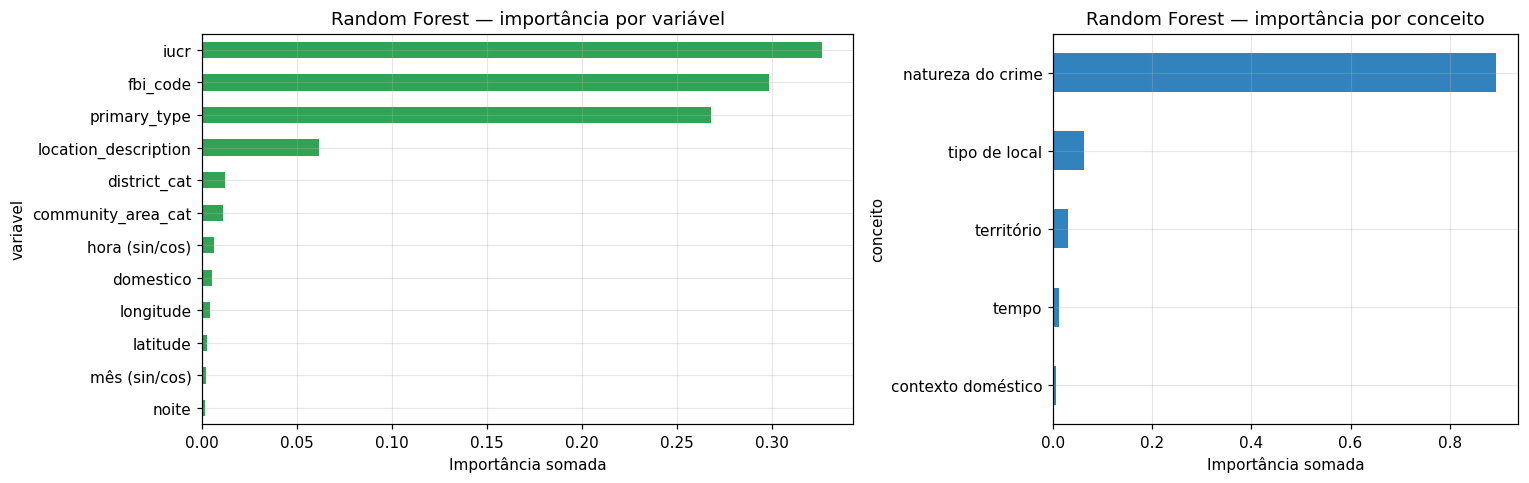

,importancia
conceito,
natureza do crime,0.8932
tipo de local,0.0615
território,0.0291
tempo,0.0110
contexto doméstico,0.0052


Códigos IUCR que MAIS AUMENTAM a chance de prisão (LR):


,iucr,tipo,descricao,coeficiente,odds_ratio,n_treino,pct_prisao
84,5111,OTHER OFFENSE,GUN OFFENDER - ANNUAL REGISTRATION,4.024,55.938,1405.0,98.4
119,5110,OTHER OFFENSE,GUN OFFENDER - DUTY TO REGISTER,3.536,34.346,516.0,97.5
115,0554,ASSAULT,"AGGRAVATED POLICE OFFICER - HANDS, FISTS, FEET...",3.443,31.284,650.0,83.4
53,0454,BATTERY,"AGGRAVATED P.O. - HANDS, FISTS, FEET, NO / MIN...",3.323,27.741,2616.0,84.9
142,0461,BATTERY,"AGGRAVATED P.O. - HANDS, FISTS, FEET, SERIOUS ...",2.660,14.300,338.0,85.5
184,5112,OTHER OFFENSE,GUN OFFENDER - DUTY TO REPORT CHANGE OF INFORM...,2.533,12.585,161.0,95.0
55,1210,DECEPTIVE PRACTICE,THEFT OF LABOR / SERVICES,2.147,8.562,2558.0,29.5
185,5131,OTHER OFFENSE,VIOLENT OFFENDER - ANNUAL REGISTRATION,2.146,8.547,160.0,83.8


Códigos IUCR que MAIS REDUZEM a chance de prisão (LR):


,iucr,tipo,descricao,coeficiente,odds_ratio,n_treino,pct_prisao
24,1477,WEAPONS VIOLATION,RECKLESS FIREARM DISCHARGE,-4.224,0.015,9881.0,3.0
19,2825,OTHER OFFENSE,HARASSMENT BY TELEPHONE,-3.702,0.025,11991.0,0.7
81,141B,WEAPONS VIOLATION,UNLAWFUL USE - OTHER FIREARM,-3.663,0.026,1432.0,3.6
21,2826,OTHER OFFENSE,HARASSMENT BY ELECTRONIC MEANS,-3.542,0.029,11726.0,0.7
33,0870,THEFT,POCKET-PICKING,-2.978,0.051,6151.0,0.4
147,3400,PUBLIC PEACE VIOLATION,LOOTING,-2.687,0.068,315.0,1.9
14,2820,OTHER OFFENSE,TELEPHONE THREAT,-2.579,0.076,16451.0,0.8
35,1152,DECEPTIVE PRACTICE,ILLEGAL USE CASH CARD,-2.376,0.093,5395.0,0.2


Maiores efeitos do contexto (local, território, tempo), fora da natureza do crime:


,atributo,coeficiente,odds_ratio,n_treino
213,district_cat_vec_61,-1.617,0.199,1493.0
73,location_description_vec_OTHER RAILROAD PROPER...,1.599,4.946,610.0
66,location_description_vec_AIRPORT TERMINAL LOWE...,1.465,4.326,783.0
33,location_description_vec_DESCONHECIDO,-1.370,0.254,6561.0
71,location_description_vec_SPORTS ARENA / STADIUM,1.300,3.668,657.0
42,location_description_vec_NURSING / RETIREMENT ...,-1.228,0.293,3467.0
75,location_description_vec_APPLIANCE STORE,1.187,3.277,600.0
82,location_description_vec_AIRPORT TERMINAL UPPE...,1.179,3.252,481.0
59,location_description_vec_CURRENCY EXCHANGE,1.165,3.206,1066.0
44,location_description_vec_CTA PLATFORM,1.137,3.116,3166.0


Obs.: n_treino vazio (NaN) = atributo numérico ou categoria 'desconhecida' sem contagem direta.


In [34]:
# --- Random Forest: importâncias por variável e por conceito ---
imp = pd.DataFrame({"atributo": NOMES, "importancia": modelo_rf.stages[-1].featureImportances.toArray()})
imp["variavel"] = imp["atributo"].map(variavel_original)                  # soma as colunas one-hot de cada variável
imp_var = imp.groupby("variavel")["importancia"].sum().sort_values(ascending=False)

# iucr, fbi_code e primary_type descrevem a MESMA coisa (a natureza do crime): agrupamos por conceito
GRUPO_CONCEITO = {"primary_type": "natureza do crime", "iucr": "natureza do crime", "fbi_code": "natureza do crime",
                  "location_description": "tipo de local",
                  "district_cat": "território", "community_area_cat": "território",
                  "latitude": "território", "longitude": "território",
                  "hora (sin/cos)": "tempo", "dia da semana (sin/cos)": "tempo", "mês (sin/cos)": "tempo",
                  "fim_de_semana": "tempo", "noite": "tempo", "domestico": "contexto doméstico"}
imp["conceito"] = imp["variavel"].map(GRUPO_CONCEITO).fillna(imp["variavel"])
imp_conceito = imp.groupby("conceito")["importancia"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.4, 1]})
imp_var.head(12)[::-1].plot.barh(ax=ax[0], color="#31a354")
ax[0].set_title("Random Forest — importância por variável"); ax[0].set_xlabel("Importância somada")
imp_conceito[::-1].plot.barh(ax=ax[1], color="#3182bd")
ax[1].set_title("Random Forest — importância por conceito"); ax[1].set_xlabel("Importância somada")
plt.tight_layout(); plt.show()
display(imp_conceito.round(4).to_frame("importancia"))

# --- Regressão Logística: coeficientes e odds ratio (= exp(coeficiente)) ---
coef = pd.DataFrame({"atributo": NOMES, "coeficiente": modelo_lr.stages[-1].coefficients.toArray()})
coef["odds_ratio"] = np.exp(coef["coeficiente"])

# Frequência de cada código IUCR no treino, para saber se um coeficiente extremo vem de um código RARO
freq = (train_df.groupBy("iucr").agg(F.count("*").alias("n_treino"),
                                     F.round(F.avg("label") * 100, 1).alias("pct_prisao")).toPandas())
nomes_iucr = (raw.groupBy("iucr").agg(F.first("primary_type").alias("tipo"),
                                      F.first("description").alias("descricao")).toPandas())
c_iucr = coef[coef["atributo"].str.startswith("iucr_vec_")].copy()
c_iucr["iucr"] = c_iucr["atributo"].str.replace("iucr_vec_", "", regex=False)
c_iucr = c_iucr.merge(freq, on="iucr", how="left").merge(nomes_iucr, on="iucr", how="left")
cols = ["iucr", "tipo", "descricao", "coeficiente", "odds_ratio", "n_treino", "pct_prisao"]
print("Códigos IUCR que MAIS AUMENTAM a chance de prisão (LR):")
display(c_iucr.sort_values("coeficiente", ascending=False).head(8)[cols].round(3))
print("Códigos IUCR que MAIS REDUZEM a chance de prisão (LR):")
display(c_iucr.sort_values("coeficiente").head(8)[cols].round(3))

# Efeitos do CONTEXTO (fora da natureza do crime): local, território e tempo.
# Acrescentamos `n_treino` (frequência da categoria no treino): um efeito grande com poucas ocorrências é frágil,
# pois a regularização quase nula deixa coeficientes de categorias raras assumirem valores extremos.
fora = coef[~coef["atributo"].str.startswith(("iucr_vec_", "fbi_code_vec_", "primary_type_vec_"))].copy()
fcat = []
for c in ["location_description", "district_cat", "community_area_cat"]:
    t = train_df.groupBy(c).count().toPandas()
    t["atributo"] = c + "_vec_" + t[c].astype(str)
    fcat.append(t[["atributo", "count"]].rename(columns={"count": "n_treino"}))
fora = fora.merge(pd.concat(fcat), on="atributo", how="left")
fora["abs"] = fora["coeficiente"].abs()
print("Maiores efeitos do contexto (local, território, tempo), fora da natureza do crime:")
display(fora.sort_values("abs", ascending=False).head(10)[["atributo", "coeficiente", "odds_ratio", "n_treino"]].round(3))
print("Obs.: n_treino vazio (NaN) = atributo numérico ou categoria 'desconhecida' sem contagem direta.")

**Cuidados na leitura dos coeficientes:** (1) a regularização escolhida é quase nula, então categorias **raras** (de código IUCR, de local ou de distrito) podem receber coeficientes extremos; por isso as tabelas mostram `n_treino` (e `pct_prisao` para o IUCR), e um extremo com poucas ocorrências deve ser lido com cautela; (2) `iucr`, `fbi_code` e `primary_type` são colineares (descrevem a mesma natureza do crime), então o coeficiente de uma categoria específica **não** é um efeito isolado; (3) os coeficientes descrevem associação com o registro de prisão, não causa.

### 7.6 Desempenho por tipo de ocorrência

O resultado global pode esconder diferenças grandes. Alguns crimes só aparecem na base **porque** a polícia fez a prisão em flagrante (o registro e a prisão são quase o mesmo evento), então prever "prisão" para eles é fácil. Já em crimes **reportados depois pela vítima** (furto, agressão, dano...), a prisão é incerta, e é aí que um modelo seria realmente útil. Comparamos os dois grupos:

> 💡 **Por que fazer assim? Benefícios:** uma métrica global pode ser inflada por um grupo "fácil". Separar os grupos mostra **onde** o modelo agrega valor real, e não só onde a resposta já está embutida no tipo do crime.

In [35]:
GRUPO_FLAGRANTE = ["NARCOTICS", "OTHER NARCOTIC VIOLATION", "PROSTITUTION", "GAMBLING", "WEAPONS VIOLATION",
                   "LIQUOR LAW VIOLATION", "CONCEALED CARRY LICENSE VIOLATION", "INTERFERENCE WITH PUBLIC OFFICER"]
GRUPO_VITIMA = ["THEFT", "BATTERY", "CRIMINAL DAMAGE", "ASSAULT", "BURGLARY", "MOTOR VEHICLE THEFT",
                "ROBBERY", "DECEPTIVE PRACTICE"]
ROT_FLAGRANTE = "Tipicamente em flagrante (iniciativa policial)"
ROT_VITIMA = "Reportados pela vítima (furto, agressão, dano...)"

linhas = []
info_grupos = {}     # (nº de ocorrências, prevalência) de cada grupo no teste; usado na leitura automática (7.9)
for rotulo, tipos in [(ROT_FLAGRANTE, GRUPO_FLAGRANTE), (ROT_VITIMA, GRUPO_VITIMA)]:
    for nome, pred in [("Baseline 2 (só tipo)", pred_base), ("Regressão Logística", pred_lr), ("Random Forest", pred_rf)]:
        sub = pred.filter(col("primary_type").isin(tipos))     # só as predições dos tipos do grupo
        n_sub, prev_sub = sub.agg(F.count("*"), F.avg("label")).first()
        if n_sub == 0 or prev_sub in (0.0, 1.0):               # AUC exige as duas classes presentes
            continue
        info_grupos[rotulo] = (n_sub, prev_sub)
        linhas.append({"Grupo": rotulo, "Modelo": nome, "ocorrências": n_sub, "% com prisão": round(prev_sub * 100, 1),
                       "AUC-ROC": round(ev_roc.evaluate(sub), 4), "AUC-PR": round(ev_pr.evaluate(sub), 4)})
tab_grupos = pd.DataFrame(linhas).set_index(["Grupo", "Modelo"])
display(tab_grupos)

ocorrências  \
Grupo                                             Modelo                              
Tipicamente em flagrante (iniciativa policial)    Baseline 2 (só tipo)        18284   
                                                  Regressão Logística         18284   
                                                  Random Forest               18284   
Reportados pela vítima (furto, agressão, dano...) Baseline 2 (só tipo)       233596   
                                                  Regressão Logística        233596   
                                                  Random Forest              233596   

                                                                        % com prisão  \
Grupo                                             Modelo                               
Tipicamente em flagrante (iniciativa policial)    Baseline 2 (só tipo)          79.4   
                                                  Regressão Logística           79.4   
                                                  Random Forest                 79.4   
Reportados pela vítima (furto, agressão, dano...) Baseline 2 (só tipo)           7.9   
                                                  Regressão Logística            7.9   
                                                  Random Forest                  7.9   

                                                                        AUC-ROC  \
Grupo                                             Modelo                          
Tipicamente em flagrante (iniciativa policial)    Baseline 2 (só tipo)   0.7635   
                                                  Regressão Logística    0.9329   
                                                  Random Forest          0.9149   
Reportados pela vítima (furto, agressão, dano...) Baseline 2 (só tipo)   0.6800   
                                                  Regressão Logística    0.8040   
                                                  Random Forest          0.7923   

                                                                        AUC-PR  
Grupo                                             Modelo                        
Tipicamente em flagrante (iniciativa policial)    Baseline 2 (só tipo)  0.9318  
                                                  Regressão Logística   0.9708  
                                                  Random Forest         0.9650  
Reportados pela vítima (furto, agressão, dano...) Baseline 2 (só tipo)  0.1395  
                                                  Regressão Logística   0.2999  
                                                  Random Forest         0.2793

### 7.7 Treinar no passado e testar no futuro

A divisão aleatória mistura anos no treino e no teste. Na prática, um modelo é usado para ocorrências **futuras**. Refazendo o experimento com a Regressão Logística (mais barata) treinando em **todos os anos menos o último** e testando **no último ano**, com pesos recalculados só no novo treino.

> 💡 **Por que fazer assim? Benefícios:** a divisão temporal simula o uso real e revela se o modelo depende de padrões que "vazam" entre anos. Se o desempenho se mantém, há mais confiança de que ele generaliza para o futuro. **Nota:** o AUC-PR depende da prevalência (que muda entre anos); por isso, nessa comparação, o **AUC-ROC** é a referência mais limpa.

In [36]:
# Treino = todos os anos antes do último; teste = o último ano completo (ANO_FIM).
train_t = df_limpo.filter(col("year") < ANO_FIM)
test_t = df_limpo.filter(col("year") == ANO_FIM)
train_t, _ = adicionar_pesos(train_t)             # pesos recalculados SÓ com o novo treino

modelo_lr_t = pipe_lr.copy(melhor_lr).fit(train_t)   # Pipeline inteiro refeito (imputer, índices, scaler...) só no passado
pred_t = modelo_lr_t.transform(test_t)
prev_t = test_t.agg(F.avg("label")).first()[0]

comparacao = pd.DataFrame({
    "Divisão": ["Aleatória 80/20 (todos os anos)", f"Temporal (treino < {ANO_FIM}, teste = {ANO_FIM})"],
    "AUC-ROC": [tabela_final.loc["Regressão Logística", "AUC-ROC"], ev_roc.evaluate(pred_t)],
    "AUC-PR": [tabela_final.loc["Regressão Logística", "AUC-PR"], ev_pr.evaluate(pred_t)],
    "Prevalência no teste": [prev_teste, prev_t]}).set_index("Divisão").round(4)
display(comparacao)

,AUC-ROC,AUC-PR,Prevalência no teste
Divisão,,,
Aleatória 80/20 (todos os anos),0.8893,0.7032,0.1371
"Temporal (treino < 2025, teste = 2025)",0.8841,0.7018,0.1615


### 7.8 Quanto o contexto acrescenta? (ablação)

A importância das variáveis sugere que a natureza do crime domina. Para quantificar, foi treinada a regressão logística (com os melhores hiperparâmetros) **acrescentando blocos de atributos**: primeiro só a natureza do crime (`primary_type`, `iucr`, `fbi_code`), depois o tipo de local, o território e, por fim, o tempo e o contexto doméstico (modelo completo). A comparação é **descritiva** (feita no teste, sem ser usada para escolher o modelo).

> 💡 **Por que fazer assim? Benefícios:** a **ablação** (acrescentar blocos de atributos) mede a contribuição **real** de cada grupo, algo que a importância de variáveis sozinha só sugere. Ela também separa dois efeitos que costumam ser confundidos: **o quão detalhado é o código do crime** (tipo primário × IUCR/FBI) e **o contexto** (local, território, tempo).

In [37]:
def pipeline_lr(cats, nums):
    """Pipeline de regressão logística usando só as categóricas (cats) e numéricas (nums) indicadas.
    Reaproveita as mesmas etapas do modelo completo, mudando apenas QUAIS atributos entram."""
    idx = StringIndexer(inputCols=cats, outputCols=[c + "_idx" for c in cats], handleInvalid="keep")
    enc = OneHotEncoder(inputCols=[c + "_idx" for c in cats], outputCols=[c + "_vec" for c in cats], handleInvalid="keep")
    stages = [sql_feat, imputer, idx, enc]
    cols_final = [c + "_vec" for c in cats]
    if nums:   # numéricas só entram quando indicadas (passo 3 em diante)
        stages += [VectorAssembler(inputCols=nums, outputCol="f_num"),
                   StandardScaler(inputCol="f_num", outputCol="f_num_s", withMean=True, withStd=True)]
        cols_final = ["f_num_s"] + cols_final
    stages += [VectorAssembler(inputCols=cols_final, outputCol="features"), lr]
    return Pipeline(stages=stages).copy(melhor_lr)


tipo = ["primary_type", "iucr", "fbi_code"]            # "natureza do crime" em 3 níveis de detalhe
passos = [
    ("1) só natureza do crime (tipo, IUCR, FBI)", tipo, []),
    ("2) + tipo de local", tipo + ["location_description"], []),
    ("3) + território (distrito, área, lat/lon)",
     tipo + ["location_description", "district_cat", "community_area_cat"], ["lat_imp", "lon_imp"]),
]
linhas_abl = []
for nome, cats, nums in passos:
    p = pipeline_lr(cats, nums).fit(train_df).transform(test_df)   # treina no TREINO, avalia no TESTE
    linhas_abl.append({"Atributos usados": nome, "AUC-ROC": ev_roc.evaluate(p), "AUC-PR": ev_pr.evaluate(p)})
# O passo 4 é o modelo completo, já treinado e avaliado: reaproveitamos o resultado
linhas_abl.append({"Atributos usados": "4) + hora/dia/mês e doméstico (modelo completo)",
                   "AUC-ROC": tabela_final.loc["Regressão Logística", "AUC-ROC"],
                   "AUC-PR": tabela_final.loc["Regressão Logística", "AUC-PR"]})
tab_abl = pd.DataFrame(linhas_abl).set_index("Atributos usados")
display(tab_abl.round(4))

ganho = tab_abl.iloc[3] - tab_abl.iloc[0]
print(f"Natureza do crime sozinha: AUC-PR = {tab_abl.iloc[0]['AUC-PR']:.3f}; modelo completo: {tab_abl.iloc[3]['AUC-PR']:.3f} "
      f"(ganho do contexto: {ganho['AUC-PR']:+.3f} de AUC-PR e {ganho['AUC-ROC']:+.3f} de AUC-ROC)")

,AUC-ROC,AUC-PR
Atributos usados,,
"1) só natureza do crime (tipo, IUCR, FBI)",0.8817,0.6958
2) + tipo de local,0.8863,0.6995
"3) + território (distrito, área, lat/lon)",0.8881,0.7025
4) + hora/dia/mês e doméstico (modelo completo),0.8893,0.7032


Natureza do crime sozinha: AUC-PR = 0.696; modelo completo: 0.703 (ganho do contexto: +0.007 de AUC-PR e +0.008 de AUC-ROC)


### 7.9 O que os resultados significam para a pergunta de negócio

A célula abaixo **gera a interpretação com os números desta execução** (nada aqui é digitado à mão). Se a base for atualizada ou os modelos forem retreinados, o texto impresso muda junto com os resultados. Os itens respondem às perguntas centrais:

1. Há sinal preditivo além do acaso?
2. De onde vem o desempenho: do **tipo** do crime, do **detalhe do código** do crime ou do **contexto**?
3. Modelo linear ou não linear?
4. Em que tipo de ocorrência o modelo é realmente útil?
5. Qual é a troca entre precisão e recall, e o desempenho se mantém no tempo?

In [38]:
# ===== Leitura automática dos resultados: interpretação gerada a partir das tabelas desta execução =====
lr_m = tabela_final.loc["Regressão Logística"]
rf_m = tabela_final.loc["Random Forest"]
b1 = tabela_final.iloc[0]
b2 = tabela_final.loc["Baseline 2 — LR só com tipo de crime"]

# ---------- 1) Sinal preditivo ----------
print("1) HÁ SINAL PREDITIVO ALÉM DO ACASO?")
print(f"   Regressão Logística: AUC-PR = {lr_m['AUC-PR']:.3f} contra {prev_teste:.3f} de um modelo sem poder preditivo "
      f"({lr_m['AUC-PR'] / prev_teste:.1f}x) e AUC-ROC = {lr_m['AUC-ROC']:.3f}.")
print(f"   Random Forest:       AUC-PR = {rf_m['AUC-PR']:.3f} ({rf_m['AUC-PR'] / prev_teste:.1f}x) e AUC-ROC = {rf_m['AUC-ROC']:.3f}.")
print(f"   Recall da classe prisão: LR {lr_m['Recall (cl. 1)']:.1%} | RF {rf_m['Recall (cl. 1)']:.1%}. "
      f"Precisão: LR {lr_m['Precisão (cl. 1)']:.1%} | RF {rf_m['Precisão (cl. 1)']:.1%}.")
acc_max = max(lr_m["Acurácia"], rf_m["Acurácia"])
print(f"   Acurácia dos modelos: LR {lr_m['Acurácia']:.1%} | RF {rf_m['Acurácia']:.1%}, contra {b1['Acurácia']:.1%} de 'sempre sem prisão' -> "
      + ("a acurácia NÃO serve aqui (o modelo inútil tem acurácia maior)." if acc_max < b1["Acurácia"]
         else "nesta execução a acurácia dos modelos supera a do 'sempre sem prisão', mas ela continua enganosa com classes desbalanceadas."))

# ---------- 2) De onde vem o desempenho ----------
a = tab_abl["AUC-PR"].values
r = tab_abl["AUC-ROC"].values
print("\n2) DE ONDE VEM O DESEMPENHO? (camadas de informação, AUC-PR no teste)")
print(f"   a) só o TIPO primário (Baseline 2):                  AUC-PR = {b2['AUC-PR']:.3f} | AUC-ROC = {b2['AUC-ROC']:.3f}")
print(f"   b) + detalhe do código (IUCR e FBI) = natureza total: AUC-PR = {a[0]:.3f} | AUC-ROC = {r[0]:.3f}   (ganho sobre (a): {a[0] - b2['AUC-PR']:+.3f})")
print(f"   c) + local, território, tempo e doméstico (completo): AUC-PR = {a[3]:.3f} | AUC-ROC = {r[3]:.3f}   (ganho sobre (b): {a[3] - a[0]:+.3f})")
print(f"      -> local {a[1] - a[0]:+.3f}, território {a[2] - a[1]:+.3f}, tempo/doméstico {a[3] - a[2]:+.3f}")
print(f"   Conclusão: o detalhe do código do crime responde por {(a[0] - b2['AUC-PR']) / (a[3] - b2['AUC-PR']):.0%} do ganho do modelo completo sobre o Baseline 2; "
      f"o contexto (local+território+tempo) responde por apenas {(a[3] - a[0]) / (a[3] - b2['AUC-PR']):.0%}.")
print("   Importância na Random Forest por conceito: " + ", ".join(f"{k} {v:.0%}" for k, v in imp_conceito.items()))

# ---------- 3) Linear x não linear ----------
dif = lr_m["AUC-PR"] - rf_m["AUC-PR"]
print("\n3) LINEAR × NÃO LINEAR")
if abs(dif) < LIMITE_EMPATE:
    veredito = f"LR e RF ficaram praticamente empatadas (diferença de {abs(dif):.4f} no AUC-PR)"
elif dif > 0:
    veredito = f"a Regressão Logística superou a Random Forest (AUC-PR {lr_m['AUC-PR']:.3f} contra {rf_m['AUC-PR']:.3f})"
else:
    veredito = f"a Random Forest superou a Regressão Logística (AUC-PR {rf_m['AUC-PR']:.3f} contra {lr_m['AUC-PR']:.3f})"
print(f"   {veredito}; a RF levou {tempo_rf / tempo_lr:.0f}x mais tempo para treinar ({tempo_rf:.0f} s contra {tempo_lr:.0f} s).")
if melhor_rf[rf.maxDepth] == max(VALORES_DEPTH):
    print(f"   Ressalva: a RF ficou limitada pela profundidade máxima testada ({max(VALORES_DEPTH)}, na borda da grade); "
          "não dá para afirmar que interações entre atributos não ajudariam.")
else:
    print("   A profundidade escolhida da RF ficou no interior da grade.")

# ---------- 4) Onde o modelo é útil ----------
print("\n4) ONDE O MODELO É ÚTIL? (desempenho por tipo de ocorrência)")
n_fl, p_fl = info_grupos[ROT_FLAGRANTE]
n_vi, p_vi = info_grupos[ROT_VITIMA]
share_fl = n_fl * p_fl / (prev_teste * n_test)
print(f"   Em flagrante: {n_fl:,} ocorrências no teste, {p_fl:.1%} com prisão ({share_fl:.0%} de todas as prisões do teste).")
fl = tab_grupos.loc[ROT_FLAGRANTE]
print(f"     AUC-PR: LR {fl.loc['Regressão Logística', 'AUC-PR']:.3f} | baseline do tipo {fl.loc['Baseline 2 (só tipo)', 'AUC-PR']:.3f} -> a prisão já está quase embutida no tipo.")
vi = tab_grupos.loc[ROT_VITIMA]
print(f"   Reportados pela vítima: {n_vi:,} ocorrências, {p_vi:.1%} com prisão (o caso mais incerto e mais informativo).")
print(f"     AUC-PR: LR {vi.loc['Regressão Logística', 'AUC-PR']:.3f} ({vi.loc['Regressão Logística', 'AUC-PR'] / p_vi:.1f}x o acaso) | "
      f"RF {vi.loc['Random Forest', 'AUC-PR']:.3f} | baseline do tipo {vi.loc['Baseline 2 (só tipo)', 'AUC-PR']:.3f}")
print(f"     AUC-ROC: LR {vi.loc['Regressão Logística', 'AUC-ROC']:.3f} | baseline do tipo {vi.loc['Baseline 2 (só tipo)', 'AUC-ROC']:.3f}")
_part_detalhe = (a[0] - b2["AUC-PR"]) / (a[3] - b2["AUC-PR"])
if _part_detalhe > 0.5:
    print(f"     Atenção: o ganho do modelo sobre o baseline do tipo vem principalmente do detalhe do código (IUCR/FBI), "
          f"que responde por {_part_detalhe:.0%} do ganho global (item 2), e não do contexto.")

# ---------- 5) Precisão x recall e tempo ----------
print("\n5) PRECISÃO × RECALL E ESTABILIDADE NO TEMPO")
for lim in [0.5, 0.6]:
    if lim in sens_rf.index:
        print(f"   RF com limiar {lim}: precisão {sens_rf.loc[lim, 'precisão']:.1%} | recall {sens_rf.loc[lim, 'recall']:.1%} | F1 {sens_rf.loc[lim, 'F1']:.3f}")
lim_f1 = sens_rf["F1"].idxmax()
print(f"   Entre os limiares testados, o maior F1 da RF é {sens_rf.loc[lim_f1, 'F1']:.3f}, no limiar {lim_f1} "
      "(descritivo: em produção o limiar seria escolhido numa base de validação, conforme o custo dos erros).")
print("   Lembrete: com pesos de classe, a 'probabilidade' do modelo não é calibrada; o limiar 0,5 não equivale a 50% de chance real.")
tt = comparacao.iloc[1]
print(f"   Validação temporal (treino < {ANO_FIM}, teste = {ANO_FIM}): AUC-ROC = {tt['AUC-ROC']:.3f} (aleatória: {comparacao.iloc[0]['AUC-ROC']:.3f}); "
      f"AUC-PR = {tt['AUC-PR']:.3f} (prevalência {tt['Prevalência no teste']:.1%} contra {comparacao.iloc[0]['Prevalência no teste']:.1%}).")
dif_roc = abs(tt["AUC-ROC"] - comparacao.iloc[0]["AUC-ROC"])
print("   -> " + ("desempenho estável no tempo (AUC-ROC quase igual)." if dif_roc < 0.02
                  else f"o AUC-ROC mudou {dif_roc:.3f} entre as divisões: há alguma sensibilidade ao período."))

1) HÁ SINAL PREDITIVO ALÉM DO ACASO?
   Regressão Logística: AUC-PR = 0.703 contra 0.137 de um modelo sem poder preditivo (5.1x) e AUC-ROC = 0.889.
   Random Forest:       AUC-PR = 0.686 (5.0x) e AUC-ROC = 0.879.
   Recall da classe prisão: LR 79.5% | RF 77.2%. Precisão: LR 38.2% | RF 38.2%.
   Acurácia dos modelos: LR 79.5% | RF 79.7%, contra 86.3% de 'sempre sem prisão' -> a acurácia NÃO serve aqui (o modelo inútil tem acurácia maior).

2) DE ONDE VEM O DESEMPENHO? (camadas de informação, AUC-PR no teste)
   a) só o TIPO primário (Baseline 2):                  AUC-PR = 0.584 | AUC-ROC = 0.803
   b) + detalhe do código (IUCR e FBI) = natureza total: AUC-PR = 0.696 | AUC-ROC = 0.882   (ganho sobre (a): +0.112)
   c) + local, território, tempo e doméstico (completo): AUC-PR = 0.703 | AUC-ROC = 0.889   (ganho sobre (b): +0.007)
      -> local +0.004, território +0.003, tempo/doméstico +0.001
   Conclusão: o detalhe do código do crime responde por 94% do ganho do modelo completo sobre o B

### 7.10 Limitações e cuidados

- **`arrest` é um resultado do processo policial, e não do crime em si.** O modelo aprende **onde e como a polícia atua e registra**. Áreas e tipos de crime mais policiados terão mais prisões, e isso pode **reproduzir vieses** de policiamento. Os atributos de território (`district`, `community_area`, latitude/longitude) funcionam como *proxies* e exigem cuidado. **O modelo não deve ser usado para decisões sobre pessoas ou bairros específicos** sem uma análise de equidade.
- **Informação posterior.** O campo `arrest` e a classificação do crime (IUCR) podem ser atualizados **depois** do registro. Os dados mais recentes tendem a estar menos completos. A validação temporal (7.7) ajuda a medir isso, mas não elimina o problema.
- **A natureza do crime domina, e é parcialmente circular.** O resultado diz que a prisão é, em grande parte, determinada pela natureza do crime. Em crimes em flagrante (narcóticos, armas), a própria categoria nasce da ação policial, e o código IUCR pode ser atribuído ou revisado depois do registro. Isso não invalida o modelo, mas o torna mais descritivo do que operacional.
- **Dados de data/hora e de localização imprecisos.** A documentação da base informa que a data é, por vezes, uma estimativa aproximada (há horários padrão, como meia-noite e meio-dia) e que as coordenadas são deslocadas por redação parcial (dentro do mesmo quarteirão). Isso enfraquece o efeito da hora e da posição.
- **Recorte e escopo.** Os resultados valem para Chicago, em 2020–2025 (inclui a pandemia e mudanças no policiamento). Não se generalizam a outras cidades ou épocas sem nova validação.
- **Escopo computacional.** A busca de hiperparâmetros usa uma fração do treino e uma grade pequena, para caber no Colab. Se o melhor valor de um hiperparâmetro ficar na borda da grade (a célula de verificação da seção 6.1 avisa quando isso acontece), o modelo poderia melhorar com uma busca maior. Com um cluster, a grade e a fração poderiam crescer.

---
## 8. Persistência do modelo treinado

Foi salvo o **`PipelineModel` completos** (pré-processamento + classificador) com `save()`. O modelo escolhido é a **regressão logística** (melhor AUC-PR e muito mais barata de treinar); a Random Forest também é salva, para comparação. Como as variáveis temporais fazem parte do Pipeline, o modelo carregado recebe a ocorrência "crua" e refaz todas as transformações.

In [39]:
caminho_lr = f"{DIR_MODELOS}/modelo_lr_prisao_chicago"
caminho_rf = f"{DIR_MODELOS}/modelo_rf_prisao_chicago"
modelo_lr.write().overwrite().save(caminho_lr)    # modelo escolhido
modelo_rf.write().overwrite().save(caminho_rf)    # alternativo, para comparação
print("Modelos salvos em:", caminho_lr, "e", caminho_rf)

# Recarrega o modelo escolhido e confere: as predições devem ser idênticas às do modelo em memória
modelo_lr_carregado = PipelineModel.load(caminho_lr)
amostra_check = test_df.limit(5000).cache()
amostra_check.count()
original = modelo_lr.transform(amostra_check).select("id", col("prediction").alias("p_orig"))
recarregado = modelo_lr_carregado.transform(amostra_check).select("id", col("prediction").alias("p_novo"))
divergentes = original.join(recarregado, "id").filter(col("p_orig") != col("p_novo")).count()
print(f"Predições divergentes após recarregar o modelo: {divergentes}")
print("✅ O modelo salvo reproduz exatamente as predições." if divergentes == 0 else "⚠️ Há divergências: investigue o salvamento.")

#  Exemplo de uso: uma ocorrência nova, com as colunas "cruas" (o Pipeline faz o resto)
from datetime import datetime
from pyspark.sql.types import TimestampType
esquema_novo = StructType([
    StructField("data_ocorrencia", TimestampType()), StructField("primary_type", StringType()),
    StructField("iucr", StringType()), StructField("location_description", StringType()),
    StructField("fbi_code", StringType()), StructField("district_cat", StringType()),
    StructField("community_area_cat", StringType()), StructField("domestic", BooleanType()),
    StructField("latitude", DoubleType()), StructField("longitude", DoubleType())])
nova = spark.createDataFrame([(datetime(2025, 6, 14, 23, 30), "BATTERY", "0486", "STREET", "08B",
                               "11", "25", False, 41.88, -87.76)], esquema_novo)
(modelo_lr_carregado.transform(nova)
 .select("primary_type", "location_description",
         vector_to_array("probability")[1].alias("escore_prisao"), "prediction")   # escore ponderado: NÃO é probabilidade calibrada
 .show(truncate=False))

# from google.colab import drive; drive.mount('/content/drive')
# !cp -r /content/modelos /content/drive/MyDrive/modelos_sparkml

Modelos salvos em: /content/modelos/modelo_lr_prisao_chicago e /content/modelos/modelo_rf_prisao_chicago
Predições divergentes após recarregar o modelo: 0
✅ O modelo salvo reproduz exatamente as predições.
+------------+--------------------+-------------------+----------+
|primary_type|location_description|escore_prisao      |prediction|
+------------+--------------------+-------------------+----------+
|BATTERY     |STREET              |0.43217261609052227|0.0       |
+------------+--------------------+-------------------+----------+



---
## 9. Conclusão

A célula abaixo monta o resumo com os **números da sua execução**.

In [40]:
#  Resumo final: todos os números vêm das variáveis calculadas nesta execução
melhor_nome = tabela_final.loc[["Regressão Logística", "Random Forest"], "AUC-PR"].idxmax()   # só os modelos completos
m = tabela_final.loc[melhor_nome]
b2 = tabela_final.loc["Baseline 2 — LR só com tipo de crime"]
outro = "Random Forest" if melhor_nome == "Regressão Logística" else "Regressão Logística"
o = tabela_final.loc[outro]
a = tab_abl["AUC-PR"].values

print(f"Base: Chicago Crimes {ANO_INICIO}–{ANO_FIM}, {n_limpo:,} ocorrências após a limpeza "
      f"(de {total_base:,} na base completa, 2001 até hoje).")
print(f"Alvo: prisão (arrest). Prevalência: {prev_teste:.1%} → problema desbalanceado.\n")
print(f"Melhor modelo (AUC-PR no teste): {melhor_nome}")
print(f"  • AUC-ROC = {m['AUC-ROC']:.3f}  | AUC-PR = {m['AUC-PR']:.3f}  (acaso = {prev_teste:.3f})")
print(f"  • Classe 'prisão': precisão = {m['Precisão (cl. 1)']:.3f}, recall = {m['Recall (cl. 1)']:.3f}, F1 = {m['F1 (cl. 1)']:.3f}")
print(f"  • {outro}: AUC-ROC = {o['AUC-ROC']:.3f}, AUC-PR = {o['AUC-PR']:.3f}")
print(f"  • Baseline só com o tipo primário: AUC-ROC = {b2['AUC-ROC']:.3f}, AUC-PR = {b2['AUC-PR']:.3f}")
print(f"  • Natureza do crime completa (tipo+IUCR+FBI): AUC-PR = {a[0]:.3f}; com todo o contexto: {a[3]:.3f} "
      f"(o contexto acrescenta só {a[3] - a[0]:+.3f})")
print(f"  • Validação temporal (LR, treino < {ANO_FIM}, teste = {ANO_FIM}): "
      f"AUC-ROC = {comparacao.iloc[1]['AUC-ROC']:.3f}, AUC-PR = {comparacao.iloc[1]['AUC-PR']:.3f}")
print("  • Importância por conceito (RF): " +
      ", ".join(f"{k} {v:.0%}" for k, v in imp_conceito.head(4).items()))
print(f"  • Tempo de treino: LR {tempo_lr:.0f} s | RF {tempo_rf:.0f} s")

Base: Chicago Crimes 2020–2025, 1,425,373 ocorrências após a limpeza (de 8,671,708 na base completa, 2001 até hoje).
Alvo: prisão (arrest). Prevalência: 13.7% → problema desbalanceado.

Melhor modelo (AUC-PR no teste): Regressão Logística
  • AUC-ROC = 0.889  | AUC-PR = 0.703  (acaso = 0.137)
  • Classe 'prisão': precisão = 0.382, recall = 0.795, F1 = 0.516
  • Random Forest: AUC-ROC = 0.879, AUC-PR = 0.686
  • Baseline só com o tipo primário: AUC-ROC = 0.803, AUC-PR = 0.584
  • Natureza do crime completa (tipo+IUCR+FBI): AUC-PR = 0.696; com todo o contexto: 0.703 (o contexto acrescenta só +0.007)
  • Validação temporal (LR, treino < 2025, teste = 2025): AUC-ROC = 0.884, AUC-PR = 0.702
  • Importância por conceito (RF): natureza do crime 89%, tipo de local 6%, território 3%, tempo 1%
  • Tempo de treino: LR 57 s | RF 2177 s


### 9.1 Resumo

Os **números** do resumo estão na célula de código acima (gerados a cada execução). Em termos de **interpretação**:

- **Há sinal preditivo bem acima do acaso**, e o modelo linear (regressão logística) é competitivo com a Random Forest, sendo muito mais barato de treinar.
- A **natureza do crime**, principalmente o **nível de detalhe do código** (`iucr`, `fbi_code`), concentra quase todo o poder de previsão. **Local, território e horário acrescentam pouco** (a ablação da seção 7.8 quantifica isso).
- O desempenho é **estável ao treinar no passado e testar no último ano**, o que dá mais confiança de que o modelo generaliza no tempo.
- Para os crimes **reportados pela vítima** (o caso mais incerto), o modelo supera o baseline do tipo, mas esse ganho vem **principalmente do detalhe do código do crime**, e não do contexto.
- Os resultados descrevem **como a polícia atua e registra**, e não a probabilidade de um crime "terminar em prisão" por si só (ver limitações, seção 7.10).


